# Learning when to hedge

**Impulse control of a Bachelier call by deep stochastic optimisation, with an exact benchmark**

A desk hedges a call at discrete dates and pays a fixed charge every time it trades. The questions are *when* to rehedge and *how far*. This notebook

1. states the problem as an impulse control problem and reduces it, exactly, to tracking the frictionless hedge;
2. solves it exactly by dynamic programming, which is possible here because the state has three dimensions;
3. learns the policy by stochastic gradient descent through simulation, with a network that outputs a no-trade band;
4. compares the learned policy with the exact one, in cost and state by state;
5. takes the learned policy apart: which laws it recovered, where its remaining errors sit, which of its features matter, and what its hidden layer encodes.

Part I is the methodology and is self-contained. Parts II to V are the implementation, the results, the interpretability analysis and a summary. Sections are numbered through the whole notebook: 1 to 8 methodology, 9 to 16 implementation and checks, 17 and 18 results, 19 to 25 interpretability, 26 and 27 summary.

**Running it.** Everything runs top to bottom. Training dominates the run time: the eight networks of 3,000 iterations took about 2.7 hours of CPU time on the two-core machine used here (22 to 25 minutes per network with the replay estimator, 13 to 17 with the score function). With `IMPULSE_REUSE=1` in the environment the notebook reloads the networks saved in `cache/` by an earlier run instead of training again. The outputs stored in this copy were produced that way, from networks trained earlier by the same code; everything else is computed in the run, which then takes about eleven minutes. `IMPULSE_QUICK=1` runs a smoke test with small budgets, whose numbers mean nothing. The code selects a GPU when one is present, but it has only been run on a CPU. Figures are also written to `figures/` as PNG files.

# Part I. Methodology

## 1. Setting

The market is the Bachelier model with zero rates, $dS_t=\sigma\,dW_t$. Trading dates are $t_k=k\,\Delta t$ for $k=0,\dots,N$, with $\Delta t=T/N$. The claim is a call, $H=(S_T-K)^+$. A hedge is a sequence $\theta_0,\dots,\theta_{N-1}$: $\theta_k$ is the position held over $[t_k,t_{k+1})$ and may depend on everything observed up to $t_k$. With initial capital $w$, the terminal hedging error is

$$\varepsilon_T(\theta)=H-w-\sum_{k=0}^{N-1}\theta_k\,\Delta S_k,\qquad \Delta S_k=S_{k+1}-S_k .$$

Numbers: $S_0=3.00\%$, $\sigma=80$ bp per year, $T=1$ year, $K=S_0$, $N=100$. All computations use the normalised price $x=(S-K)/(\sigma\sqrt T)$, in which $\sigma=1$ and $T=1$. Prices are then in units of $\sigma\sqrt T$ (80 bp) and squared errors in units of $\sigma^2T$. The hedge ratio is dimensionless and is not rescaled.

## 2. Quadratic hedging is a tracking problem

Write $V_k=\mathbb E[H\mid\mathcal F_k]$. The frictionless variance-optimal hedge is the one-step regression coefficient

$$\theta^\star_k=\frac{\operatorname{Cov}_k(V_{k+1},\Delta S_k)}{\operatorname{Var}_k(\Delta S_k)},\qquad w^\star=V_0 .$$

**Identity.** For every hedge $\theta$, with $w=V_0$,

$$\mathbb E\big[\varepsilon_T(\theta)^2\big]=\mathbb E\big[\varepsilon_T(\theta^\star)^2\big]+\mathbb E\sum_{k=0}^{N-1}(\theta_k-\theta^\star_k)^2\,\operatorname{Var}_k(\Delta S_k).$$

*Proof.* Since $H-V_0=\sum_k\Delta V_k$, the error is $\varepsilon_T(\theta)=\sum_k(\Delta V_k-\theta_k\Delta S_k)$, a sum of martingale differences, so the cross terms between different dates have zero expectation. For one date write

$$\Delta V_k-\theta_k\Delta S_k=(\Delta V_k-\theta^\star_k\Delta S_k)-(\theta_k-\theta^\star_k)\,\Delta S_k .$$

The first bracket is the residual of the regression of $\Delta V_k$ on $\Delta S_k$ given $\mathcal F_k$, so it is conditionally uncorrelated with $\Delta S_k$, and $\theta_k-\theta^\star_k$ is known at $t_k$. Hence $\mathbb E_k[(\Delta V_k-\theta_k\Delta S_k)^2]=\mathbb E_k[(\Delta V_k-\theta^\star_k\Delta S_k)^2]+(\theta_k-\theta^\star_k)^2\operatorname{Var}_k(\Delta S_k)$. Summing over $k$ gives the identity. $\square$

The first term on the right does not depend on the hedge: it is the error of discrete rebalancing itself. Everything a hedge can influence is the second term, the squared distance from $\theta^\star$ weighted by the local variance of the price. In the Bachelier model both ingredients are explicit. $\operatorname{Var}_k(\Delta S_k)=\sigma^2\Delta t$, and by Stein's lemma and the heat equation

$$\theta^\star_k=\Phi(d_k),\qquad d_k=\frac{S_k-K}{\sigma\sqrt{T-t_k}},$$

exactly, on any grid. So no network is needed for $\theta^\star$ in this notebook. The identity itself needs only that $S$ is a martingale; in the SABR notebook $\theta^\star$ is the learned hedge (Bartlett's delta).

Section 12 checks the identity by simulation.

## 3. A charge per trade

Suppose each trade costs a fixed amount $\lambda$, whatever its size. Where does the charge enter? If it is simply paid out of wealth, a hedge that trades on every date pays the constant $(N-1)\lambda$, and the free capital $w$ absorbs a constant: the quadratic criterion would not notice the charge at all. It has to be priced against variance explicitly:

$$J(\pi)=\underbrace{\mathbb E\sum_{k=0}^{N-1}(\theta_k-\theta^\star_k)^2\,\sigma^2\Delta t}_{\mathrm{MSHE}(\theta)-\mathrm{MSHE}(\theta^\star)}\;+\;\lambda\;\mathbb E\,\#\{k\ge 1:\theta_k\neq\theta_{k-1}\}.$$

$\lambda$ is the exchange rate between one trade and hedging variance. Equivalently, $J$ is the Lagrangian of "minimise the mean-square hedging error subject to a budget on the expected number of trades", and $\lambda$ is the multiplier.

Conventions: the position starts at $\theta_0=\theta^\star_0$ free of charge, decisions are taken at $k=1,\dots,N-1$, and nothing is charged at expiry. The main level is $\lambda=2.5\times10^{-4}\,\sigma^2T$, about a fifth of the frictionless mean-square error on this grid; $10^{-4}$ and $5\times10^{-4}$ are used to test scaling.

## 4. The control problem and its exact solution

At date $k$ the state is $(S_k,\theta_{k-1})$: the position carried into the date is part of the state, because whether a trade is worth $\lambda$ depends on where the position already is. The action is to hold, or to pay $\lambda$ and move to any position $\theta'$.

Let $C_k(S,\theta)$ be the expected cost of *holding* $\theta$ from $t_k$ to $t_{k+1}$ and acting optimally afterwards, and $V_k$ the optimal cost:

$$C_k(S,\theta)=(\theta-\theta^\star_k(S))^2\,\sigma^2\Delta t+\mathbb E\big[V_{k+1}(S_{k+1},\theta)\mid S_k=S\big],$$

$$V_k(S,\theta)=\min\Big\{\,C_k(S,\theta),\;\;\lambda+\min_{\theta'}C_k(S,\theta')\Big\},\qquad V_N\equiv 0 .$$

This is the discrete-time form of a quasi-variational inequality. The alternative to waiting is not a fixed payoff, as in optimal stopping, but the value function itself at another point, plus $\lambda$.

**Shape of the solution.** At each $(k,S)$ the optimal policy is described by three numbers:

* the target $m_k(S)=\arg\min_{\theta'}C_k(S,\theta')$;
* the no-trade interval $[\ell_k(S),u_k(S)]=\{\theta:\ C_k(S,\theta)\le\lambda+\min_{\theta'}C_k(S,\theta')\}$, which contains the target.

Inside the interval you hold; outside you jump to the target. *When* is the first exit from the interval, *how far* is the distance to the target. The target does not depend on where the position comes from, because the charge does not depend on the size of the trade.

**Numerics.** $V$ is computed backward on a grid of $501\times501$ points in $(x,\theta)$. The conditional expectation is a convolution with a Gaussian kernel in $x$. Triggers and target are refined between grid nodes (linear root, parabolic vertex). One solve takes a few seconds on a CPU. The solution is checked by simulating the resulting policy: its Monte Carlo cost must equal the value $V$ at inception (Sections 11 and 12).

## 5. What theory predicts

Two elementary arguments give the band in two regimes. Neither is shown to the network. They are used as benchmarks and, in Part IV, as hypotheses about what the network has learned.

**Near the money: the renewal argument.** Over a short stretch of time the mis-hedge $\delta=\theta-\theta^\star$ moves like a Brownian motion with variance rate $q^2=\Gamma^2\sigma^2$, because $d\theta^\star=\Gamma\,dS+\dots$. Carrying it costs $\sigma^2\delta^2$ per unit time. Suppose it is reset to zero whenever $|\delta|$ reaches $b$, for a charge $\lambda$. A cycle lasts $b^2/q^2$ on average and accrues a tracking cost $\sigma^2b^4/(6q^2)$, so the cost per unit time is

$$\frac{\sigma^2b^4/(6q^2)+\lambda}{b^2/q^2}=\frac{\sigma^2b^2}{6}+\frac{\lambda q^2}{b^2},\qquad\text{minimised by}\qquad b=\Big(\frac{6\lambda q^2}{\sigma^2}\Big)^{1/4}=(6\lambda)^{1/4}\sqrt{\Gamma}.$$

It predicts a band proportional to $\lambda^{1/4}$ and to $\sqrt\Gamma$, with $\Gamma_k=\phi(d_k)/(\sigma\sqrt{T-t_k})$; a trading intensity $q^2/b^2=\sigma^2\Gamma/\sqrt{6\lambda}$; and equal spending on tracking error and on charges.

Integrated over the life of the option, the intensity gives the number of trades. For a strike at the money, $\mathbb E[\Gamma_t]=\phi(0)/(\sigma\sqrt T)$ at every date, so

$$\mathbb E[\#\text{trades}]\approx\int_0^T\frac{\sigma^2\,\mathbb E[\Gamma_t]}{\sqrt{6\lambda}}\,dt=\frac{\phi(0)\,\sigma\sqrt T}{\sqrt{6\lambda}},$$

which is $\phi(0)/\sqrt{6\lambda}$ in normalised units: 16.3, 10.3 and 7.3 trades at the three charge levels used here.

**The grid.** The position is inspected only every $\Delta t$, so the mis-hedge overshoots the trigger before a trade happens. For barrier monitoring, inspecting at discrete dates is equivalent to moving the barrier by $\beta$ one-step standard deviations, $\beta=-\zeta(1/2)/\sqrt{2\pi}\approx0.5826$ (Broadie, Glasserman and Kou, 1997). The one-step standard deviation of $\theta^\star$ is $\Gamma\sigma\sqrt{\Delta t}$, which suggests the trigger

$$b^{\text{near}}_k=(6\lambda)^{1/4}\sqrt{\Gamma_k}-\beta\,\Gamma_k\,\sigma\sqrt{\Delta t}.$$

**Far from the money: the break-even argument.** Where $\Gamma$ is negligible the target no longer moves, and the renewal argument, which sends the band to zero, is the wrong picture. Carrying a mis-hedge $\delta$ to expiry then costs $\sigma^2\delta^2(T-t)$, and removing it costs $\lambda$. A trade pays for itself only if

$$|\delta|>b^{\text{far}}_k=\sqrt{\frac{\lambda}{\sigma^2\,(T-t_k)}} .$$

**Two-regime rule.** Taking the larger of the two, $b_k=\max(b^{\text{near}}_k,b^{\text{far}}_k)$, with target $\theta^\star$, gives a closed-form rule. It was not in the plan for this notebook: the regret analysis of Section 21 shows that the near-the-money formula alone loses almost all of its ten percent far from the money, by trading where the exact rule holds, and the break-even floor is what removes that loss. It is included among the reference rules from the start so that the learned policy is measured against the strongest formula available.

All of these are leading-order statements. They hold for small bands and away from expiry near the money.

## 6. Deep stochastic optimisation

### 6.1 The policy

One network serves all dates: two inputs, two hidden layers of 64 units with SiLU activations, and three outputs $o_1,o_2,o_3$. The inputs are $d_k/2$, with $d_k$ clipped at $\pm6$, and $\sqrt{(T-t_k)/T}$. The outputs are turned into a target and two triggers,

$$m_k=\operatorname{clip}\big(\theta^\star_k+c,\,0,\,1\big),\qquad \ell_k=m_k-h^-,\qquad u_k=m_k+h^+,$$

$$c=0.1\tanh o_3,\qquad h^-=0.1\operatorname{softplus}(o_1),\qquad h^+=0.1\operatorname{softplus}(o_2),$$

so the two half-widths are positive and the target offset is bounded by $0.1$. At initialisation $h^\pm\approx0.07$ and $c\approx0$.

The deployed rule, called the *hard rule* below, is: trade to $m_k$ if and only if $\theta_{k-1}\notin[\ell_k,u_k]$. This is exactly the shape of the exact solution in Section 4, with three free functions of $(t,S)$. The network is given neither $\Gamma$ nor any of the formulas of Section 5.

### 6.2 Why backpropagation alone cannot learn the triggers

On a simulated path, given the dates on which trades happen, the cost is a smooth function of the targets, and backpropagation through the simulation gives its gradient. With respect to the triggers the picture is different. Moving a trigger slightly changes nothing unless it flips a decision, and then the cost jumps. On every path the cost is piecewise constant in $(\ell,u)$, so its pathwise derivative is zero almost surely, while the derivative of the *expected* cost is not. The difficulty lies in the gradient estimator, not in the problem.

One tempting repair is to smooth the rule itself and trade a fraction of the way. That restores a pathwise gradient but changes the problem, since a fractional trade pays a fractional charge, which is a proportional cost. In a one-parameter version of this problem it converged to a band that was 4% too expensive, and its sensitivities exploded when the smoothing was sharpened. It is not used here.

### 6.3 Randomised decisions

During training the decision is drawn at random:

$$p_k=\operatorname{sigm}\!\Big(\frac{\ell_k-\theta_{k-1}}{\epsilon}\Big)+\operatorname{sigm}\!\Big(\frac{\theta_{k-1}-u_k}{\epsilon}\Big),\qquad y_k\sim\operatorname{Bernoulli}(p_k),\qquad \theta_k=y_k\,m_k+(1-y_k)\,\theta_{k-1}.$$

A trade is still a full trade at the full charge; only the decision is noisy. Let $J_\epsilon(\phi)$ be the expected cost under this rule for network weights $\phi$. As $\epsilon\to0$ it becomes the cost of the hard rule. $\epsilon$ is annealed geometrically from $0.04$ to $0.005$ in delta units, against a band of about $0.1$.

### 6.4 The gradient

Let $c_k=(\theta_k-\theta^\star_k)^2\sigma^2\Delta t+\lambda y_k$ be the cost of date $k$, and $Q^a_k$ the expected cost from date $k$ on when action $a$ is taken at $k$ ($a=1$ trade, $a=0$ hold) and the randomised policy is followed afterwards. Then

$$\nabla_\phi J_\epsilon=\mathbb E\Big[\sum_k\nabla_\phi c_k\Big|_{y\text{ fixed}}\Big]+\mathbb E\Big[\sum_k\nabla_\phi p_k\,\big(Q^1_k-Q^0_k\big)\Big].$$

The first term is ordinary backpropagation through the positions with the sampled decisions held fixed: it is the gradient for *how far*. The second is the gradient for *when*: raising the probability of trading at date $k$ is worth the difference between trading and holding there. $\nabla_\phi p_k$ is itself an ordinary derivative, through the triggers and through the position carried into the date.

*Derivation.* The expected cost from date $k$ on is $W_k=p_kQ^1_k+(1-p_k)Q^0_k$. Differentiating, $\nabla W_k=\nabla p_k\,(Q^1_k-Q^0_k)+p_k\nabla Q^1_k+(1-p_k)\nabla Q^0_k$, and $Q^a_k=c_k(a)+\mathbb E[W_{k+1}]$, where the next state depends on $\phi$ only through the position. Unrolling over $k$ gives the two sums.

### 6.5 Two estimators of the timing term

**Replay.** The market does not react to the hedge. For a given date on a simulated path, the cost of the action that was *not* taken can therefore be obtained by replaying the position recursion alone from that date, on the same prices and with the same random numbers for later decisions, until both branches trade on the same date, after which they coincide. Realised minus counterfactual cost is a one-sample unbiased estimate of $\pm(Q^1_k-Q^0_k)$. Branches are replayed for a random subset of (path, date) pairs, chosen with probability proportional to $p_k(1-p_k)$, which is proportional to the size of $\nabla p_k$, and reweighted by the inverse probability. That keeps the estimator unbiased at a fixed cost per path.

**Score function.** Because $\nabla p_k\,(Q^1_k-Q^0_k)=\mathbb E_{y_k}\big[\nabla\log\pi_k(y_k)\,Q^{y_k}_k\big]$, the timing term can also be estimated by $\nabla\log\pi_k(y_k)\,(G_k-\bar G_k)$, where $G_k$ is the realised cost from date $k$ on and $\bar G_k$ a baseline, here the batch mean per date. It needs no replay and remains valid when the market does react to the hedge, but it is noisier. It is run as an ablation on the same budget.

Both are implemented as surrogate losses for automatic differentiation, with $\operatorname{sg}$ denoting stop-gradient:

$$\frac1M\sum_{\text{paths}}\Big[\sum_kc_k+\sum_kp_k\,\operatorname{sg}\big(\widehat{Q^1_k-Q^0_k}\big)\Big]\qquad\text{and}\qquad\frac1M\sum_{\text{paths}}\Big[\sum_kc_k+\sum_k\log\pi_k(y_k)\,\operatorname{sg}\big(G_k-\bar G_k\big)\Big].$$

Section 15 checks both against finite differences of $J_\epsilon$.

### 6.6 Training and evaluation protocol

Adam with learning rate $2\times10^{-3}$ and cosine decay to 5% of it, 3,000 iterations of 2,048 fresh paths, three seeds per estimator. The replay estimator replays about 20 branches per path and iteration, out of the 99 dates. Every policy, learned or not, is evaluated with the hard rule on the same $2^{17}$ price paths, so that differences in cost are paired and their standard errors small.

## 7. How the trained policy is interrogated

Because an exact solution exists, the statements below about what the network has learned can be checked rather than suggested. Six levels are examined.

1. **Function.** The policy is three surfaces over $(t,S)$. They are plotted against the exact ones, with the differences (Section 19).
2. **Laws.** Does the band obey $b=a\,\lambda^{\kappa}\sqrt\Gamma-B\,\Gamma\sigma\sqrt{\Delta t}$ near the money, with $\kappa=\tfrac14$, $a=6^{1/4}$, $B=\beta$, and $b=\sqrt{\lambda/(\sigma^2(T-t))}$ far from it? The fits use visited states and the three charge levels, for the learned and the exact policy (Section 20).
3. **Decisions.** For any policy $\pi$, with $Q^\star$ and $V^\star$ the exact action-value and value functions,
$$J(\pi)-J^\star=\mathbb E_\pi\sum_k\big[Q^\star_k(s_k,a_k)-V^\star_k(s_k)\big].$$
Each term is non-negative and is the regret of one decision. *Proof:* $Q^\star_k(s_k,a_k)=c_k+\mathbb E[V^\star_{k+1}(s_{k+1})\mid s_k,a_k]$, so the sum telescopes to $\sum_kc_k-V^\star_1(s_1)$ in expectation. The regret of a decision splits into three kinds: a trade the exact rule would not make, a trade it would make that was missed, and a trade to the wrong target. The gap to the optimum is attributed to kinds, times and moneyness (Section 21).
4. **Components.** One learned feature at a time is removed (the target offset, the asymmetry of the band, everything but a fitted formula) and the policy is re-priced. The same is done to the exact policy, which shows what each feature is worth at best. In the other direction, the band is replaced by the closed-form rule of Section 5 while the policy keeps its own target, which tests whether errors in the band and errors in the target are separable (Section 22).
5. **Representation.** The triggers are a linear read-out of the last hidden layer followed by a softplus. Linear probes test whether $\sqrt\Gamma$ and other quantities can be read linearly from that layer, against two controls: the raw inputs and an untrained network. A causal test follows: one quantity is erased linearly from the hidden layer and the resulting policy is re-priced (Section 23).
6. **Behaviour.** The number of trades on a path against the gamma met on that path, which tests the trading intensity predicted in Section 5; the distribution of the number of trades and of their sizes; and one path (Section 24).

Section 25 then compares the two gradient estimators by their noise.

## 8. What is and is not claimed

* The benchmark is exact for the discrete problem up to grid error, which is measured by simulation.
* Statements about the learned policy hold for this model, this contract and the three charge levels tested.
* The learned policy minimises $J_\epsilon$ at $\epsilon=0.005$, not the hard-rule cost; the difference is part of its measured gap.
* The formulas of Section 5 are heuristics on a grid of 100 dates. Their accuracy is measured, not assumed.
* With two inputs, the representation level is the least informative of the six. A network of this size keeps every function of its inputs in some non-linear form, and the tests of Section 23 are worded accordingly.
* Not covered: proportional costs, risk measures other than the quadratic one, stochastic volatility, and books of several claims.

**References.** Bensoussan and Lions, *Impulse Control and Quasi-Variational Inequalities* (1984). Broadie, Glasserman and Kou, "A continuity correction for discrete barrier options", *Mathematical Finance* (1997). Whalley and Wilmott, "Optimal hedging of options with small but arbitrary transaction cost structure", *European Journal of Applied Mathematics* (1999). Fukasawa, "Discretization error of stochastic integrals", *Annals of Applied Probability* (2011). Han and E, "Deep learning approximation for stochastic control problems" (2016). Deschatre and Mikael, "Deep combinatorial optimisation for optimal stopping time problems and stochastic impulse control" (2020).

# Part II. Implementation

## 9. Set-up

In [1]:
import os, sys, math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.stats import norm

QUICK = os.environ.get("IMPULSE_QUICK", "0") == "1"     # smoke-test budgets; set IMPULSE_QUICK=1 to try the notebook fast
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# contract and market in physical units (used for reporting only)
S0_PCT, SIGMA_BP, T_YEARS = 3.00, 80.0, 1.0

# normalised units used throughout: x = (S - K)/(sigma sqrt(T)), sigma = 1, T = 1, strike at x = 0
N = 100                       # rebalancing dates t_k = k/N
DT = 1.0 / N
SD = math.sqrt(DT)            # standard deviation of one step of x
KD = N - 1                    # decision dates k = 1, ..., N-1
BGK = 0.5826                  # discrete-monitoring constant -zeta(1/2)/sqrt(2 pi)

LAMS = [1.0e-4, 2.5e-4, 5.0e-4]   # charge per trade, in units of (sigma sqrt T)^2
LAM = 2.5e-4                      # main level
SEEDS = [1, 2] if QUICK else [1, 2, 3]
ITERS = 300 if QUICK else 3000
BATCH = 1024 if QUICK else 2048
EVAL_PATHS = 2**14 if QUICK else 2**17
EPS0, EPS1 = 0.04, 0.005      # randomisation width in delta units, annealed geometrically
LR = 2.0e-3
LOSS_SCALE = 1.0e3            # the costs are O(1e-3); rescale so gradients are O(1)
REPLAY_BRANCHES_PER_PATH = 20 # counterfactual branches replayed per path and iteration (out of 99 dates)
REUSE_TRAINED = os.environ.get("IMPULSE_REUSE", "0") == "1"   # reload networks saved by an earlier run instead of training
CACHE_DIR = "cache"
os.makedirs(CACHE_DIR, exist_ok=True)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
print(f"device: {DEVICE} | quick mode: {QUICK} | {ITERS} iterations x {BATCH} paths | {EVAL_PATHS} evaluation paths")

device: cpu | quick mode: False | 3000 iterations x 2048 paths | 131072 evaluation paths


In [2]:
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRAY, INK, INK2, GRID = "#898781", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 9.5,
    "axes.titlesize": 10.5, "axes.titleweight": "regular", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": GRAY, "ytick.color": GRAY, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2.0, "lines.solid_capstyle": "round",
    "legend.frameon": False, "legend.fontsize": 9, "figure.facecolor": "white", "axes.facecolor": "white",
})

def finish(fig, name, rect=None):
    """Tighten, save a PNG for slides, and display. `rect` leaves room for a figure-level legend."""
    fig.tight_layout(rect=rect)
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [3]:
def pct(a, b):
    """Relative difference in percent."""
    return 100.0 * (a / b - 1.0)

def tau_of(k):
    """Time to expiry at date k."""
    return 1.0 - np.asarray(k, dtype=float) * DT

def theta_star(k, x):
    """Frictionless variance-optimal hedge of the call at date k: the Bachelier delta, exact on any grid."""
    return norm.cdf(x / np.sqrt(tau_of(k)))

def gamma_of(k, x):
    """Bachelier gamma in normalised units."""
    t = tau_of(k)
    return norm.pdf(x / np.sqrt(t)) / np.sqrt(t)

KS = np.arange(1, N)                                   # decision dates
TAUS = tau_of(KS)                                      # (KD,)

def market_paths(M, seed):
    """Normalised price paths at the decision dates, shape (M, KD); column j is date k = j + 1."""
    rng = np.random.default_rng(seed)
    return np.cumsum(SD * rng.standard_normal((M, KD)), axis=1).astype(np.float32)

def targets_on(X):
    """theta* and gamma along paths X of shape (M, KD)."""
    d = X / np.sqrt(TAUS)[None, :]
    return norm.cdf(d).astype(np.float32), (norm.pdf(d) / np.sqrt(TAUS)[None, :]).astype(np.float32)

## 10. Exact benchmark by dynamic programming

The function below implements Section 4 of the methodology. It also stores the holding cost $C_k(x,\theta)$ for every date, which is the exact action-value function used in the regret analysis: $Q^\star_k(s,\text{hold})=C_k(x,\theta)$ and $Q^\star_k(s,\text{trade to }\theta')=\lambda+C_k(x,\theta')$.

In [4]:
def solve_dp(lam, dx=0.02, dth=0.002, xmax=5.0):
    """Exact solution of the fixed-charge tracking problem on a grid in (x, theta).

    Returns the value at inception, the lower trigger, upper trigger and target for every date and x,
    and the cost-of-holding function C_k(x, theta) used later as the exact Q-function.
    """
    xs = np.arange(-xmax, xmax + 1e-9, dx)
    ths = np.arange(0.0, 1.0 + 1e-9, dth)
    nx, nth = len(xs), len(ths)
    J = int(round(6 * SD / dx))
    kern = np.exp(-(np.arange(-J, J + 1) * dx) ** 2 / (2 * DT))
    kern /= kern.sum()

    def expect_next(V):                                 # E[V(x + SD Z, theta)] for every theta
        P = np.pad(V, ((J, J), (0, 0)), mode="edge")
        out = np.zeros_like(V)
        for j, w in enumerate(kern):
            out += w * P[j:j + nx]
        return out

    V = np.zeros((nx, nth))
    C_all = np.zeros((N, nx, nth), dtype=np.float32)
    Cmin = np.zeros((N, nx))
    lo = np.zeros((N, nx)); hi = np.zeros((N, nx)); tg = np.zeros((N, nx))
    IM = np.zeros((N, nx), dtype=np.int64)
    idx = np.arange(nth)[None, :]
    rows = np.arange(nx)
    for k in range(N - 1, 0, -1):
        C = (ths[None, :] - theta_star(k, xs)[:, None]) ** 2 * DT + expect_next(V)
        im = C.argmin(axis=1)
        cm = C[rows, im]
        g = C - (lam + cm[:, None])                     # <= 0 where holding beats trading
        hold = g <= 0
        # the no-trade interval is the run of 'hold' nodes that contains the minimiser
        last_false = np.maximum.accumulate(np.where(~hold, idx, -1), axis=1)
        a = last_false[rows, im] + 1
        next_false = np.minimum.accumulate(np.where(~hold, idx, nth)[:, ::-1], axis=1)[:, ::-1]
        b = next_false[rows, im] - 1
        # sub-grid refinement: linear root of g at the two edges, parabolic vertex for the target
        l = ths[a].copy()
        ok = a > 0
        g0, g1 = g[rows, np.maximum(a - 1, 0)], g[rows, a]
        l[ok] = ths[a[ok] - 1] + dth * g0[ok] / (g0[ok] - g1[ok])
        u = ths[b].copy()
        ok = b < nth - 1
        g0, g1 = g[rows, b], g[rows, np.minimum(b + 1, nth - 1)]
        u[ok] = ths[b[ok]] - dth * g0[ok] / (g1[ok] - g0[ok])
        m = ths[im].copy()
        c0, c1, c2 = C[rows, np.maximum(im - 1, 0)], cm, C[rows, np.minimum(im + 1, nth - 1)]
        den = c0 - 2 * c1 + c2
        ok = (im > 0) & (im < nth - 1) & (den > 0)
        m[ok] = ths[im[ok]] + 0.5 * dth * (c0[ok] - c2[ok]) / den[ok]
        lo[k], hi[k], tg[k] = l, u, m
        V = np.where(hold, C, lam + cm[:, None])
        C_all[k] = C
        Cmin[k] = cm
        IM[k] = im
    i0 = int(np.argmin(np.abs(xs)))
    j0 = int(np.argmin(np.abs(ths - 0.5)))
    return dict(lam=lam, xs=xs, ths=ths, dx=dx, dth=dth, lo=lo, hi=hi, tg=tg, C=C_all, Cmin=Cmin, im=IM,
                J0=float(expect_next(V)[i0, j0]))

DP = {}
for lam_ in LAMS:
    t0 = time.time()
    DP[lam_] = solve_dp(lam_)
    print(f"lambda = {lam_:.1e}: exact value J* = {DP[lam_]['J0']:.6f}   ({time.time() - t0:.1f} s)")

lambda = 1.0e-04: exact value J* = 0.002630   (2.8 s)
lambda = 2.5e-04: exact value J* = 0.004498   (3.0 s)
lambda = 5.0e-04: exact value J* = 0.006618   (2.8 s)


## 11. Evaluation on common paths, and the reference rules

Every rule in this notebook has the same form: a lower trigger, a target and an upper trigger at each date, as functions of the price. One routine applies such a rule along a set of price paths that is shared by all rules. The reference rules are

* the exact optimum from the dynamic programme;
* the two-regime rule $\max(b^{\text{near}},b^{\text{far}})$ of Section 5;
* the best constant band around $\theta^\star$, which is the trader's rule "rehedge when the delta has moved by so much";
* the near-the-money formula, with and without the correction for the grid;
* the best fixed schedule, and rehedging on every date.

In [5]:
X_EVAL = market_paths(EVAL_PATHS, seed=20261113)        # common evaluation paths for every policy
TS_EVAL, GAM_EVAL = targets_on(X_EVAL)
X_VAL = market_paths(4096, seed=7)                      # small validation set used during training
TS_VAL, _ = targets_on(X_VAL)

def run_bands(X, TS, lo, m, hi, lam, keep=False):
    """Apply the hard rule 'trade to m when the position is outside [lo, hi]' along market paths.

    lo, m, hi have shape (M, KD). Returns per-path cost, tracking cost and number of trades.
    """
    M = X.shape[0]
    th = np.full(M, 0.5)
    trk = np.zeros(M); ntr = np.zeros(M)
    if keep:
        TPRE = np.empty(X.shape, dtype=np.float32); Y = np.empty(X.shape, dtype=bool)
    for j in range(KD):
        y = (th < lo[:, j]) | (th > hi[:, j])
        if keep:
            TPRE[:, j] = th; Y[:, j] = y
        th = np.where(y, m[:, j], th)
        trk += (th - TS[:, j]) ** 2 * DT
        ntr += y
    out = dict(cost=trk + lam * ntr, tracking=trk, trades=ntr)
    if keep:
        out.update(TPRE=TPRE, Y=Y)
    return out

def bands_dp(dp, X):
    lo = np.empty(X.shape, dtype=np.float32); m = np.empty_like(lo); hi = np.empty_like(lo)
    for j in range(KD):
        k = j + 1
        lo[:, j] = np.interp(X[:, j], dp["xs"], dp["lo"][k])
        m[:, j] = np.interp(X[:, j], dp["xs"], dp["tg"][k])
        hi[:, j] = np.interp(X[:, j], dp["xs"], dp["hi"][k])
    return lo, m, hi

def bands_symmetric(TS, b):
    """Band of half-width b (array or scalar) centred on theta*, target theta*."""
    b = np.maximum(b, 0.0)
    return TS - b, TS, TS + b

def bands_schedule(TS, q):
    """Rehedge to theta* every q dates and never in between."""
    lo = np.full(TS.shape, -np.inf, dtype=np.float32); hi = np.full(TS.shape, np.inf, dtype=np.float32)
    on = (KS % q) == 0
    lo[:, on] = TS[:, on] + 1.0                         # empty interval: forces a trade
    hi[:, on] = TS[:, on] - 1.0
    return lo, TS, hi

def asym_halfwidth(lam, GAM, shift):
    """Small-charge band (6 lam)^(1/4) sqrt(gamma), optionally with the discrete-monitoring shift."""
    return (6 * lam) ** 0.25 * np.sqrt(GAM) - (BGK * GAM * SD if shift else 0.0)

def break_even(lam):
    """Width at which a trade just pays for itself if the target stops moving: delta^2 (T - t) = lam."""
    return np.sqrt(lam / TAUS)[None, :]

def two_regime_halfwidth(lam, GAM):
    """The larger of the small-charge band (with discrete shift) and the break-even width."""
    return np.maximum(asym_halfwidth(lam, GAM, True), break_even(lam))

TWO_KEY = "two-regime rule (near / break-even)"

def summarise(res, ref=None):
    c = res["cost"]
    s = dict(cost=c.mean(), se=c.std() / math.sqrt(len(c)), trades=res["trades"].mean(), tracking=res["tracking"].mean())
    if ref is not None:                                 # paired comparison on the common paths
        d = c - ref["cost"]
        s["gap_pct"] = 100 * d.mean() / ref["cost"].mean()
        s["gap_se"] = 100 * d.std() / math.sqrt(len(d)) / ref["cost"].mean()
    return s

In [6]:
def reference_table(lam, verbose=True):
    dp = DP[lam]
    res = {}
    res["exact optimum (DP)"] = run_bands(X_EVAL, TS_EVAL, *bands_dp(dp, X_EVAL), lam)
    sub = slice(0, min(EVAL_PATHS, 2**14))
    grid = np.arange(0.03, 0.31, 0.005)
    costs = [run_bands(X_EVAL[sub], TS_EVAL[sub], *bands_symmetric(TS_EVAL[sub], b), lam)["cost"].mean() for b in grid]
    b_best = float(grid[int(np.argmin(costs))])
    res[f"best constant band (+-{b_best:.3f})"] = run_bands(X_EVAL, TS_EVAL, *bands_symmetric(TS_EVAL, b_best), lam)
    res[TWO_KEY] = run_bands(X_EVAL, TS_EVAL, *bands_symmetric(TS_EVAL, two_regime_halfwidth(lam, GAM_EVAL)), lam)
    res["asymptotic band, discrete shift"] = run_bands(X_EVAL, TS_EVAL, *bands_symmetric(TS_EVAL, asym_halfwidth(lam, GAM_EVAL, True)), lam)
    res["asymptotic band"] = run_bands(X_EVAL, TS_EVAL, *bands_symmetric(TS_EVAL, asym_halfwidth(lam, GAM_EVAL, False)), lam)
    qs = range(2, 25)
    costs = [run_bands(X_EVAL[sub], TS_EVAL[sub], *bands_schedule(TS_EVAL[sub], q), lam)["cost"].mean() for q in qs]
    q_best = list(qs)[int(np.argmin(costs))]
    res[f"best fixed schedule (every {q_best} dates)"] = run_bands(X_EVAL, TS_EVAL, *bands_schedule(TS_EVAL, q_best), lam)
    res["every date"] = run_bands(X_EVAL, TS_EVAL, *bands_schedule(TS_EVAL, 1), lam)
    ref = res["exact optimum (DP)"]
    if verbose:
        print(f"lambda = {lam:.1e}   exact value by DP: {dp['J0']:.6f}")
        print(f"{'rule':37s} {'cost':>9s} {'s.e.':>9s} {'vs optimum':>11s} {'trades':>7s}")
        for name, r in res.items():
            s = summarise(r, ref)
            print(f"{name:37s} {s['cost']:9.6f} {s['se']:9.6f} {s['gap_pct']:+10.1f}% {s['trades']:7.1f}")
    return res

REF = {lam_: reference_table(lam_, verbose=(lam_ == LAM)) for lam_ in LAMS}
print()
print("exact policy simulated on the evaluation paths, against the value from the dynamic programme")
for lam_ in LAMS:
    s_ = summarise(REF[lam_]["exact optimum (DP)"])
    print(f"  lambda = {lam_:.1e}: {s_['cost']:.6f} +- {s_['se']:.6f} against {DP[lam_]['J0']:.6f} "
          f"({pct(s_['cost'], DP[lam_]['J0']):+.2f}%, {(s_['cost'] - DP[lam_]['J0']) / s_['se']:+.1f} s.e.)")

lambda = 2.5e-04   exact value by DP: 0.004498
rule                                       cost      s.e.  vs optimum  trades
exact optimum (DP)                     0.004504  0.000004       +0.0%    10.2
best constant band (+-0.100)           0.004948  0.000004       +9.8%    11.1
two-regime rule (near / break-even)    0.004551  0.000004       +1.0%    10.3
asymptotic band, discrete shift        0.004939  0.000004       +9.7%    12.0
asymptotic band                        0.005329  0.000004      +18.3%     9.0
best fixed schedule (every 5 dates)    0.009312  0.000009     +106.7%    19.0
every date                             0.024750  0.000000     +449.5%    99.0

exact policy simulated on the evaluation paths, against the value from the dynamic programme
  lambda = 1.0e-04: 0.002632 +- 0.000002 against 0.002630 (+0.08%, +1.0 s.e.)
  lambda = 2.5e-04: 0.004504 +- 0.000004 against 0.004498 (+0.14%, +1.5 s.e.)
  lambda = 5.0e-04: 0.006625 +- 0.000006 against 0.006618 (+0.10%, +1.0 s.e.)


The best fixed schedule costs about twice the optimum and the trader's constant band ten percent more. The near-the-money formula with its correction for the grid is no better than the constant band (9.7% against 9.8% above the optimum), and without the correction it is worse (18.3%). Adding the break-even floor brings it to 1.0%. Section 21 shows why.

The lines under the table check the benchmark: at the three charge levels the simulated cost of the exact policy is within 0.15% of the value computed by the dynamic programme, 1.0 to 1.5 standard errors. The three comparisons share their paths and are not independent. Section 12 repeats the check on a larger, independent sample.

## 12. Check: the tracking identity

The identity of Section 2 is tested from terminal hedging errors. The exact policy is simulated to expiry on fresh paths, the errors $\varepsilon_T(\theta)$ and $\varepsilon_T(\theta^\star)$ are computed on the same paths, and the difference of their mean squares is compared with the tracking sum. The identity is exact, so the two agree up to Monte Carlo error. The last lines are a second, independent check of the benchmark: the cost of the exact policy on these paths against the value computed by the dynamic programme.

In [7]:
def identity_check(lam, M=2**18, batches=16, seed0=1):
    """MSHE(theta) - MSHE(theta*) against the tracking sum, for the exact policy, from terminal hedging errors.

    Fresh paths, independent of the evaluation paths. Also returns the simulated cost of the exact policy,
    which is compared with the value computed by the dynamic programme.
    """
    dp = DP[lam]
    price = norm.pdf(0.0)                               # Bachelier ATM call in units of sigma sqrt(T)
    names = ("e_star2", "e_pol2", "diff", "trk", "gap", "cost")
    s1 = dict.fromkeys(names, 0.0); s2 = dict.fromkeys(names, 0.0)
    for b in range(batches):
        rng = np.random.default_rng(seed0 + b)
        x = np.zeros(M); th = np.full(M, 0.5)
        gain_star = np.zeros(M); gain_pol = np.zeros(M); trk = np.zeros(M); ntr = np.zeros(M)
        for k in range(N):
            if k > 0:
                l = np.interp(x, dp["xs"], dp["lo"][k]); u = np.interp(x, dp["xs"], dp["hi"][k])
                y = (th < l) | (th > u)
                th = np.where(y, np.interp(x, dp["xs"], dp["tg"][k]), th)
                ntr += y
            ts = theta_star(k, x)
            trk += (th - ts) ** 2 * DT
            dS = SD * rng.standard_normal(M)
            gain_star += ts * dS; gain_pol += th * dS
            x = x + dS
        H = np.maximum(x, 0.0)
        e_star = H - price - gain_star; e_pol = H - price - gain_pol
        diff = e_pol ** 2 - e_star ** 2
        for nm, v in zip(names, (e_star ** 2, e_pol ** 2, diff, trk, diff - trk, trk + lam * ntr)):
            s1[nm] += v.sum(); s2[nm] += (v ** 2).sum()
    n = M * batches
    mean = {nm: s1[nm] / n for nm in names}
    se = {nm: math.sqrt(max(s2[nm] / n - mean[nm] ** 2, 0.0) / n) for nm in names}
    print(f"{n} fresh paths")
    print(f"MSHE(theta*)             = {mean['e_star2']:.6f}   (RMSE {math.sqrt(mean['e_star2']):.4f}; call price {price:.4f})")
    print(f"MSHE(exact policy)       = {mean['e_pol2']:.6f}   (RMSE {math.sqrt(mean['e_pol2']):.4f})")
    print(f"MSHE difference          = {mean['diff']:.6f} +- {se['diff']:.6f}")
    print(f"tracking sum             = {mean['trk']:.6f} +- {se['trk']:.6f}")
    print(f"difference of the two    = {mean['gap']:+.2e} +- {se['gap']:.1e}   ({mean['gap'] / se['gap']:+.1f} standard errors)")
    print(f"cost of the exact policy = {mean['cost']:.6f} +- {se['cost']:.6f}   (dynamic programme: {dp['J0']:.6f},")
    print(f"                           {pct(mean['cost'], dp['J0']):+.3f}%, {(mean['cost'] - dp['J0']) / se['cost']:+.1f} standard errors)")
    return mean["e_star2"]

MSHE_STAR = identity_check(LAM, M=2**15 if QUICK else 2**18, batches=2 if QUICK else 16)
print(f"charge / frictionless MSHE = {LAM / MSHE_STAR:.2f}")

4194304 fresh paths
MSHE(theta*)             = 0.001205   (RMSE 0.0347; call price 0.3989)
MSHE(exact policy)       = 0.003149   (RMSE 0.0561)
MSHE difference          = 0.001944 +- 0.000002
tracking sum             = 0.001946 +- 0.000000
difference of the two    = -2.03e-06 +- 2.2e-06   (-0.9 standard errors)
cost of the exact policy = 0.004500 +- 0.000001   (dynamic programme: 0.004498,
                           +0.042%, +2.6 standard errors)
charge / frictionless MSHE = 0.21


The identity holds: on 4.2 million paths the two sides differ by $-2.0\times10^{-6}$, less than one standard error.

The cost of the exact policy on these paths is 0.04% above the value from the dynamic programme, at 2.6 standard errors. That is the numerical error of the benchmark, and it is small against the gaps of the learned policies reported below (0.75% and more). Gaps are always measured against the simulated exact policy on the same paths, so they are not affected by the error of the computed value itself.

## 13. The policy network

Two inputs, two hidden layers of 64 units, three outputs. The lower and upper half-widths pass through a softplus, the target offset through a tanh. `ConstBand` is a three-parameter policy used only for the gradient check.

In [8]:
KK_T = torch.arange(1, N, device=DEVICE, dtype=torch.float32)
SQTAU_T = torch.sqrt(1.0 - KK_T * DT)                   # sqrt(time to expiry) at the decision dates, (KD,)

class BandNet(nn.Module):
    """One network for all dates: (d, sqrt(tau)) -> lower trigger, target, upper trigger.

    The three outputs are offsets from theta*: the target is theta* + c, the triggers sit h_lo below and
    h_hi above the target. Gamma and the asymptotic formula are not given to the network.
    """
    def __init__(self, width=64, h_init=0.07, h_scale=0.10, c_max=0.10):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(2, width), nn.SiLU(), nn.Linear(width, width), nn.SiLU())
        self.head = nn.Linear(width, 3)
        self.h_scale, self.c_max = h_scale, c_max
        with torch.no_grad():
            self.head.weight.mul_(0.1)
            b = math.log(math.expm1(h_init / h_scale))
            self.head.bias.copy_(torch.tensor([b, b, 0.0]))

    def hidden(self, x, sqtau):
        d = torch.clamp(x / sqtau, -6.0, 6.0)
        return self.body(torch.stack([d / 2.0, sqtau.expand_as(d)], dim=-1)), d

    def decode(self, h, d):
        o = self.head(h)
        ts = torch.special.ndtr(d)
        m = torch.clamp(ts + self.c_max * torch.tanh(o[..., 2]), 0.0, 1.0)
        return m - self.h_scale * F.softplus(o[..., 0]), m, m + self.h_scale * F.softplus(o[..., 1]), ts

    def forward(self, x, sqtau):
        return self.decode(*self.hidden(x, sqtau))

class ConstBand(nn.Module):
    """Three free numbers (lower half-width, upper half-width, target offset); used for the gradient check."""
    def __init__(self, h_lo, h_hi, c):
        super().__init__()
        self.p = nn.Parameter(torch.tensor([h_lo, h_hi, c], dtype=torch.float32))

    def forward(self, x, sqtau):
        ts = torch.special.ndtr(x / sqtau)
        m = ts + self.p[2]
        return m - self.p[0], m, m + self.p[1], ts

def bands_from_policy(policy, X, chunk=16384):
    """Triggers and target of a torch policy on market paths X (numpy) -> numpy arrays."""
    los, ms, his = [], [], []
    with torch.no_grad():
        for s in range(0, X.shape[0], chunk):
            lo, m, hi, _ = policy(torch.as_tensor(X[s:s + chunk], dtype=torch.float32, device=DEVICE), SQTAU_T)
            los.append(lo.cpu().numpy()); ms.append(m.cpu().numpy()); his.append(hi.cpu().numpy())
    return np.concatenate(los), np.concatenate(ms), np.concatenate(his)

## 14. The two gradient estimators

`surrogate_on` simulates the randomised rule of Section 6.3 and returns a loss whose gradient is the estimate of $\nabla_\phi J_\epsilon$ from Section 6.4. `replay_delta_q` produces the counterfactual estimate of $Q^1_k-Q^0_k$ of Section 6.5.

In [9]:
def trade_prob(lo, hi, theta, eps):
    """Smoothed indicator of 'position outside [lo, hi]'; always below 1 because lo < hi."""
    return torch.sigmoid((lo - theta) / eps) + torch.sigmoid((theta - hi) / eps)

@torch.no_grad()
def replay_delta_q(lo, m, hi, ts, U, Y, TPRE, TPOST, P, eps, lam, gen, budget):
    """One-sample estimate of Q(trade) - Q(hold) on a random subset of (path, date) pairs, importance-weighted.

    The realised continuation is one branch. The other is obtained by taking the opposite action at that date and
    replaying the position recursion on the same market path with the same uniforms, until both branches trade on
    the same date (after which they coincide) or the horizon ends.

    The timing gradient weights each pair by grad p, which is proportional to p(1-p). Pairs are therefore kept with
    probability proportional to p(1-p) (capped at 1) and the estimate is divided by that probability, which keeps
    the estimator unbiased while replaying about `budget` branches instead of all M x KD.
    """
    out = torch.zeros_like(P)
    w = P * (1 - P)
    keep_prob = torch.clamp(w * (budget / w.sum().clamp_min(1e-12)), max=1.0)
    sel = (torch.rand(P.shape, generator=gen, device=P.device) < keep_prob).nonzero(as_tuple=False)
    if sel.numel() == 0:
        return out
    p0, j0 = sel[:, 0], sel[:, 1]
    y0 = Y[p0, j0]
    th = torch.where(y0, TPRE[p0, j0], m[p0, j0])       # position after the action that was not taken
    lam_t = torch.full_like(th, lam)
    D = torch.where(y0, -lam_t, lam_t) + ((th - ts[p0, j0]) ** 2 - (TPOST[p0, j0] - ts[p0, j0]) ** 2) * DT
    Dfin = torch.empty_like(D)
    slot = torch.arange(D.numel(), device=D.device)
    cp, cj = p0, j0
    while slot.numel() > 0:
        cj = cj + 1
        done = cj >= KD
        if done.any():
            Dfin[slot[done]] = D[done]
            keep = ~done
            slot, cp, cj, th, D = slot[keep], cp[keep], cj[keep], th[keep], D[keep]
            if slot.numel() == 0:
                break
        mj, tj, yb = m[cp, cj], ts[cp, cj], Y[cp, cj]
        ycf = U[cp, cj] < trade_prob(lo[cp, cj], hi[cp, cj], th, eps)
        th = torch.where(ycf, mj, th)
        D = D + lam * (ycf.float() - yb.float()) + ((th - tj) ** 2 - (TPOST[cp, cj] - tj) ** 2) * DT
        co = ycf & yb                                   # both branches trade to the same target: they coincide from here
        if co.any():
            Dfin[slot[co]] = D[co]
            keep = ~co
            slot, cp, cj, th, D = slot[keep], cp[keep], cj[keep], th[keep], D[keep]
    out[p0, j0] = (1.0 - 2.0 * y0.float()) * Dfin / keep_prob[p0, j0]   # counterfactual minus realised -> trade minus hold
    return out

def surrogate_on(policy, X, U, eps, lam, estimator, gen, budget=None):
    """Surrogate loss whose gradient is an unbiased estimate of the gradient of the randomised objective."""
    M = X.shape[0]
    lo, m, hi, ts = policy(X, SQTAU_T)
    theta = torch.full((M,), 0.5, device=X.device)
    P, Y, TPRE, TPOST = [], [], [], []
    for j in range(KD):
        p = trade_prob(lo[:, j], hi[:, j], theta, eps)
        y = U[:, j] < p.detach()
        TPRE.append(theta)
        theta = torch.where(y, m[:, j], theta)          # gradient flows through the target, not through y
        P.append(p); Y.append(y); TPOST.append(theta)
    P = torch.stack(P, 1); Y = torch.stack(Y, 1); TPRE = torch.stack(TPRE, 1); TPOST = torch.stack(TPOST, 1)
    step = (TPOST - ts) ** 2 * DT + lam * Y.float()
    cost = step.sum(1)
    if estimator == "replay":
        dQ = replay_delta_q(lo.detach(), m.detach(), hi.detach(), ts.detach(), U, Y,
                            TPRE.detach(), TPOST.detach(), P.detach(), eps, lam, gen,
                            budget if budget is not None else REPLAY_BRANCHES_PER_PATH * M)
        timing = (P * dQ).sum() / M
    elif estimator == "score":
        Pc = P.clamp(1e-6, 1 - 1e-6)
        logpi = torch.where(Y, torch.log(Pc), torch.log1p(-Pc))
        G = torch.flip(torch.cumsum(torch.flip(step.detach(), [1]), 1), [1])      # cost from this date on
        timing = (logpi * (G - G.mean(0, keepdim=True))).sum() / M
    elif estimator == "pathwise_only":
        timing = 0.0
    else:
        raise ValueError(estimator)
    info = dict(cost=float(cost.detach().mean()), trades=float(Y.float().sum(1).mean()))
    return cost.mean() + timing, info

def surrogate(policy, M, eps, lam, gen, estimator):
    X = torch.cumsum(SD * torch.randn(M, KD, generator=gen, device=DEVICE), dim=1)
    U = torch.rand(M, KD, generator=gen, device=DEVICE)
    return surrogate_on(policy, X, U, eps, lam, estimator, gen)

@torch.no_grad()
def randomised_cost(policy, X, U, eps, lam):
    """Per-path cost under the randomised rule (no gradient); used for finite differences."""
    lo, m, hi, ts = policy(X, SQTAU_T)
    theta = torch.full((X.shape[0],), 0.5, device=X.device)
    cost = torch.zeros(X.shape[0], device=X.device)
    for j in range(KD):
        y = U[:, j] < trade_prob(lo[:, j], hi[:, j], theta, eps)
        theta = torch.where(y, m[:, j], theta)
        cost += (theta - ts[:, j]) ** 2 * DT + lam * y.float()
    return cost

## 15. Check: gradients against finite differences

The randomised objective $J_\epsilon$ is smooth in the policy parameters, so its gradient can be measured by central finite differences with common random numbers. This is done for a three-parameter policy (lower half-width, upper half-width, target offset) and compared with the two surrogate gradients. The last column backpropagates the cost alone, without a timing term: it is zero for the two triggers, which is the failure described in Section 6.2.

In [10]:
def gradient_check(lam, eps=0.02, n_fd=2**19, n_g=2**17, h=2.0e-3, chunk=2**14):
    """Surrogate gradients against central finite differences of the randomised objective (common random numbers)."""
    base = [0.09, 0.07, 0.01]
    names = ["lower half-width", "upper half-width", "target offset"]
    gen = torch.Generator(device=DEVICE); gen.manual_seed(99)
    est = {}
    for e in ("replay", "score", "pathwise_only"):
        gs = []
        for _ in range(max(2, n_g // chunk)):
            pol = ConstBand(*base).to(DEVICE)
            loss, _ = surrogate(pol, chunk, eps, lam, gen, e)
            loss.backward()
            gs.append(pol.p.grad.detach().cpu().numpy().copy())
        gs = np.array(gs)
        est[e] = (gs.mean(0), gs.std(0) / math.sqrt(len(gs)))
    diffs = [[] for _ in range(3)]
    for _ in range(max(2, n_fd // chunk)):
        X = torch.cumsum(SD * torch.randn(chunk, KD, generator=gen, device=DEVICE), dim=1)
        U = torch.rand(chunk, KD, generator=gen, device=DEVICE)
        for i in range(3):
            up = list(base); dn = list(base); up[i] += h; dn[i] -= h
            d = (randomised_cost(ConstBand(*up).to(DEVICE), X, U, eps, lam)
                 - randomised_cost(ConstBand(*dn).to(DEVICE), X, U, eps, lam)) / (2 * h)
            diffs[i].append(d.cpu().numpy())
    fd = np.array([np.concatenate(d).mean() for d in diffs])
    fd_se = np.array([np.concatenate(d).std() / math.sqrt(len(np.concatenate(d))) for d in diffs])
    print(f"gradient of the randomised objective, eps = {eps}, policy {base}")
    print(f"{'parameter':18s} {'finite differences':>21s} {'replay':>21s} {'score function':>21s}")
    for i in range(3):
        row = f"{names[i]:18s} {fd[i]:+10.5f} +- {fd_se[i]:.5f}"
        for e in ("replay", "score"):
            row += f" {est[e][0][i]:+10.5f} +- {est[e][1][i]:.5f}"
        print(row)
    print("backpropagating the cost alone, without a timing term: "
          + ", ".join(f"{v:+.5f}" for v in est["pathwise_only"][0]))
    return fd, fd_se, est

GC = gradient_check(LAM, n_fd=2**16 if QUICK else 2**20, n_g=2**15 if QUICK else 2**18)

gradient of the randomised objective, eps = 0.02, policy [0.09, 0.07, 0.01]
parameter             finite differences                replay        score function
lower half-width     -0.03188 +- 0.00007   -0.03182 +- 0.00005   -0.03193 +- 0.00034
upper half-width     -0.03897 +- 0.00007   -0.03910 +- 0.00003   -0.03858 +- 0.00029
target offset        +0.01043 +- 0.00003   +0.01046 +- 0.00002   +0.01054 +- 0.00013
backpropagating the cost alone, without a timing term: +0.00000, +0.00000, +0.01041


## 16. Training

Eight networks are trained: three seeds with each estimator at the main charge level, and one with the replay estimator at each of the two other levels. The validation cost is that of the hard rule on a fixed set of 4,096 paths.

In [11]:
def train(lam, seed, estimator="replay", iters=ITERS, batch=BATCH, lr=LR, verbose=True, stop_at=None):
    """Train one network. stop_at interrupts the standard schedule early (used for a partly trained network)."""
    last = (iters if stop_at is None else min(stop_at, iters)) - 1
    torch.manual_seed(seed)
    gen = torch.Generator(device=DEVICE); gen.manual_seed(1000 + seed)
    net = BandNet().to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=iters, eta_min=0.05 * lr)
    hist = dict(it=[], val=[], train=[], trades=[], eps=[])
    t0 = time.time()
    for it in range(last + 1):
        eps = EPS0 * (EPS1 / EPS0) ** (it / max(1, iters - 1))
        loss, info = surrogate(net, batch, eps, lam, gen, estimator)
        opt.zero_grad(set_to_none=True)
        (LOSS_SCALE * loss).backward()
        opt.step(); sched.step()
        if it % 50 == 0 or it == last:
            v = run_bands(X_VAL, TS_VAL, *bands_from_policy(net, X_VAL), lam)
            hist["it"].append(it); hist["val"].append(float(v["cost"].mean())); hist["train"].append(info["cost"])
            hist["trades"].append(float(v["trades"].mean())); hist["eps"].append(eps)
    hist["seconds"] = time.time() - t0
    if verbose:
        print(f"  lam {lam:.1e} seed {seed} {estimator:7s}: val. cost {hist['val'][-1]:.6f} "
              f"({pct(hist['val'][-1], DP[lam]['J0']):+.1f}% vs exact), {hist['trades'][-1]:.1f} trades, {hist['seconds']:.0f} s")
    return net, hist

def train_or_load(lam, seed, estimator):
    path = os.path.join(CACHE_DIR, f"{'quick_' if QUICK else ''}lam{lam:.1e}_{estimator}_seed{seed}.pt")
    if REUSE_TRAINED and os.path.exists(path):
        blob = torch.load(path, map_location=DEVICE, weights_only=True)     # tensors and plain numbers only
        net = BandNet().to(DEVICE)
        net.load_state_dict(blob["state"])
        h = blob["hist"]
        print(f"  lam {lam:.1e} seed {seed} {estimator:7s}: reloaded (trained in {h['seconds']:.0f} s; "
              f"val. cost {h['val'][-1]:.6f})")
        return net, h
    net, hist = train(lam, seed, estimator)
    torch.save(dict(state=net.state_dict(), hist=hist), path)
    return net, hist

In [12]:
NETS, HIST = {}, {}
for est_ in ("replay", "score"):
    for seed_ in SEEDS:
        NETS[(LAM, est_, seed_)], HIST[(LAM, est_, seed_)] = train_or_load(LAM, seed_, est_)
for lam_ in LAMS:
    if lam_ != LAM:
        NETS[(lam_, "replay", SEEDS[0])], HIST[(lam_, "replay", SEEDS[0])] = train_or_load(lam_, SEEDS[0], "replay")

  lam 2.5e-04 seed 1 replay : reloaded (trained in 1416 s; val. cost 0.004522)
  lam 2.5e-04 seed 2 replay : reloaded (trained in 1382 s; val. cost 0.004532)
  lam 2.5e-04 seed 3 replay : reloaded (trained in 1524 s; val. cost 0.004520)
  lam 2.5e-04 seed 1 score  : reloaded (trained in 1014 s; val. cost 0.004534)
  lam 2.5e-04 seed 2 score  : reloaded (trained in 807 s; val. cost 0.004548)
  lam 2.5e-04 seed 3 score  : reloaded (trained in 882 s; val. cost 0.004541)
  lam 1.0e-04 seed 1 replay : reloaded (trained in 1347 s; val. cost 0.002644)
  lam 5.0e-04 seed 1 replay : reloaded (trained in 1503 s; val. cost 0.006665)


# Part III. Results

## 17. Cost of the learned policies

In [13]:
def evaluate_net(net, lam, keep=False):
    lo, m, hi = bands_from_policy(net, X_EVAL)
    r = run_bands(X_EVAL, TS_EVAL, lo, m, hi, lam, keep=keep)
    r.update(lo=lo, m=m, hi=hi) if keep else None
    return r

RES = {}
print(f"learned policies at lambda = {LAM:.1e}, hard rule, {EVAL_PATHS} common evaluation paths")
print(f"{'policy':37s} {'cost':>9s} {'s.e.':>9s} {'vs optimum':>16s} {'trades':>7s}")
ref_ = REF[LAM]["exact optimum (DP)"]

def result_row(name, r, ref):
    s = summarise(r, ref)
    print(f"{name:37s} {s['cost']:9.6f} {s['se']:9.6f} {s['gap_pct']:+8.2f}% +- {s['gap_se']:.2f} {s['trades']:7.1f}")

for est_ in ("replay", "score"):
    for seed_ in SEEDS:
        RES[(LAM, est_, seed_)] = evaluate_net(NETS[(LAM, est_, seed_)], LAM)
        result_row(f"learned, {est_}, seed {seed_}", RES[(LAM, est_, seed_)], ref_)
for name in list(REF[LAM].keys())[:5]:
    result_row(name, REF[LAM][name], ref_)
print()
for lam_ in LAMS:
    if lam_ != LAM:
        RES[(lam_, "replay", SEEDS[0])] = evaluate_net(NETS[(lam_, "replay", SEEDS[0])], lam_)
        print(f"lambda = {lam_:.1e}")
        result_row("  learned, replay", RES[(lam_, "replay", SEEDS[0])], REF[lam_]["exact optimum (DP)"])
        for name in list(REF[lam_].keys())[:3]:
            result_row("  " + name, REF[lam_][name], REF[lam_]["exact optimum (DP)"])

learned policies at lambda = 2.5e-04, hard rule, 131072 common evaluation paths
policy                                     cost      s.e.       vs optimum  trades
learned, replay, seed 1                0.004540  0.000004    +0.79% +- 0.02    10.1
learned, replay, seed 2                0.004550  0.000004    +1.02% +- 0.02    10.1
learned, replay, seed 3                0.004538  0.000004    +0.75% +- 0.02    10.1
learned, score, seed 1                 0.004556  0.000004    +1.15% +- 0.02    10.0
learned, score, seed 2                 0.004567  0.000004    +1.38% +- 0.02    10.1
learned, score, seed 3                 0.004559  0.000004    +1.22% +- 0.02    10.0
exact optimum (DP)                     0.004504  0.000004    +0.00% +- 0.00    10.2
best constant band (+-0.100)           0.004948  0.000004    +9.84% +- 0.05    11.1
two-regime rule (near / break-even)    0.004551  0.000004    +1.04% +- 0.02    10.3
asymptotic band, discrete shift        0.004939  0.000004    +9.65% +- 0.03    12

With the replay estimator the three seeds end 0.79%, 1.02% and 0.75% above the exact optimum, with a standard error of 0.02 on each of these paired differences, and they trade 10.1 times per path against 10.2 for the exact policy. With the score-function estimator the three seeds end at 1.15% to 1.38%. For scale, the best constant band is at 9.8%.

At the two other charge levels the learned policy is 0.89% and 0.88% above the optimum.

The closed-form two-regime rule, at 1.04%, is as good as the networks. Part IV shows that the two are wrong in different places.

## 18. Training curves

Validation cost of the hard rule every 50 iterations, relative to the exact policy on the same validation paths, and the number of trades per path.

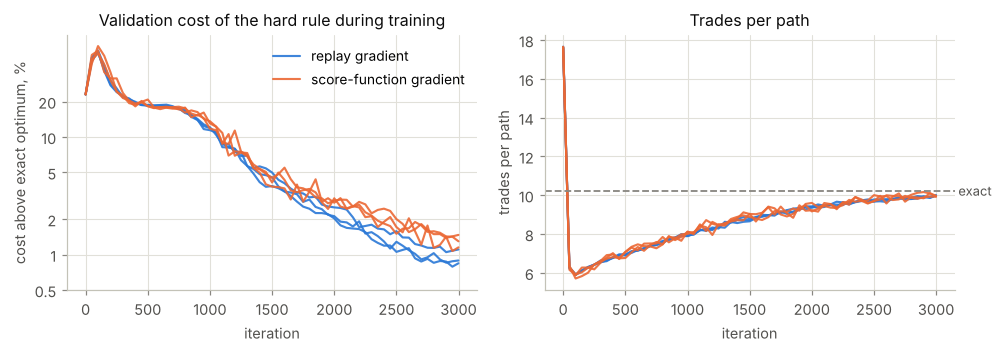

In [14]:
REF_VAL = run_bands(X_VAL, TS_VAL, *bands_dp(DP[LAM], X_VAL), LAM)["cost"].mean()   # exact policy on the validation paths
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.3))
for est_, col in (("replay", BLUE), ("score", ORANGE)):
    for i, seed_ in enumerate(SEEDS):
        h = HIST[(LAM, est_, seed_)]
        gap = np.maximum(pct(np.array(h["val"]), REF_VAL), 0.05)
        ax[0].plot(h["it"], gap, color=col, lw=1.4, alpha=0.9, label=("replay gradient" if est_ == "replay" else "score-function gradient") if i == 0 else None)
        ax[1].plot(h["it"], h["trades"], color=col, lw=1.4, alpha=0.9)
ax[0].set_yscale("log"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("cost above exact optimum, %")
ax[0].set_yticks([0.5, 1, 2, 5, 10, 20]); ax[0].set_yticklabels(["0.5", "1", "2", "5", "10", "20"]); ax[0].minorticks_off()
ax[0].set_title("Validation cost of the hard rule during training"); ax[0].legend()
ax[1].axhline(REF[LAM]["exact optimum (DP)"]["trades"].mean(), color=GRAY, lw=1.2, ls="--")
ax[1].text(ax[1].get_xlim()[1], REF[LAM]["exact optimum (DP)"]["trades"].mean(), " exact", va="center", ha="left", color=INK2, fontsize=8.5)
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("trades per path"); ax[1].set_title("Trades per path")
finish(fig, "fig_training_curves")

In the first hundred iterations the cost of the hard rule rises from about 22% to more than 50% above the optimum, while the number of trades falls from 17.6 to about 6. At the start the randomisation ($\epsilon=0.04$) is more than half the initial half-width ($0.07$): a position sitting exactly at the target still trades with probability 0.3 on each date, and the first thing the optimiser does is widen the band. As $\epsilon$ is annealed the band comes back in and the number of trades climbs towards that of the exact policy.

The cost is still falling slowly at the end, so the final gap depends on the last value of $\epsilon$ and on the length of the schedule. The runs with the score-function estimator follow the same course with more noise.

# Part IV. Interpretability

The network analysed below is the first seed trained with the replay estimator at the main charge level. Where a statement might depend on the seed or on the charge level, the other networks are used as well.

## 19. Function level: the policy as three surfaces

The policy is a map from $(t,x)$ to a lower trigger, a target and an upper trigger. With two inputs, nothing about it is hidden: it can be plotted in full and laid next to the exact solution. Triggers are shown as distances from $\theta^\star$ and are cut off at the limits 0 and 1 of the position, since a trigger beyond a limit is never reached. Only states within 2.5 standard deviations of the price are drawn.

In [15]:
SEED0 = SEEDS[0]
NET = NETS[(LAM, "replay", SEED0)]                     # the network that is taken apart below
LEARN = evaluate_net(NET, LAM, keep=True)
lo_, m_, hi_ = bands_dp(DP[LAM], X_EVAL)
EXACT = run_bands(X_EVAL, TS_EVAL, lo_, m_, hi_, LAM, keep=True)
EXACT.update(lo=lo_, m=m_, hi=hi_)
del lo_, m_, hi_
EARLY = KS <= 89                                       # dates with t < 0.9

def edge_rms(A, B, cols):
    """RMS distance between two (clipped) trigger or target arrays over visited states."""
    d = np.clip(A[:, cols], 0, 1) - np.clip(B[:, cols], 0, 1)
    return float(np.sqrt(np.mean(d.astype(np.float64) ** 2)))

print("RMS distance between learned and exact policy over visited states (delta units)")
print(f"{'':16s} {'t < 0.9':>9s} {'t >= 0.9':>9s}")
RMS = {}
for name, key in (("lower trigger", "lo"), ("upper trigger", "hi"), ("target", "m")):
    RMS[key] = (edge_rms(LEARN[key], EXACT[key], EARLY), edge_rms(LEARN[key], EXACT[key], ~EARLY))
    print(f"{name:16s} {RMS[key][0]:9.4f} {RMS[key][1]:9.4f}")
RMS_SEEDS = {SEED0: (RMS["lo"][0], RMS["hi"][0])}
for seed_ in SEEDS[1:]:
    lo_s, m_s, hi_s = bands_from_policy(NETS[(LAM, "replay", seed_)], X_EVAL[:20000])
    RMS_SEEDS[seed_] = (edge_rms(lo_s, EXACT["lo"][:20000], EARLY), edge_rms(hi_s, EXACT["hi"][:20000], EARLY))
    del lo_s, m_s, hi_s
print("triggers for t < 0.9, by seed:")
for k_, v_ in RMS_SEEDS.items():
    print(f"   seed {k_}: lower {v_[0]:.4f}, upper {v_[1]:.4f}")

RMS distance between learned and exact policy over visited states (delta units)
                   t < 0.9  t >= 0.9
lower trigger       0.0052    0.0176
upper trigger       0.0059    0.0277
target              0.0046    0.0083
triggers for t < 0.9, by seed:
   seed 1: lower 0.0052, upper 0.0059
   seed 2: lower 0.0052, upper 0.0050
   seed 3: lower 0.0073, upper 0.0066


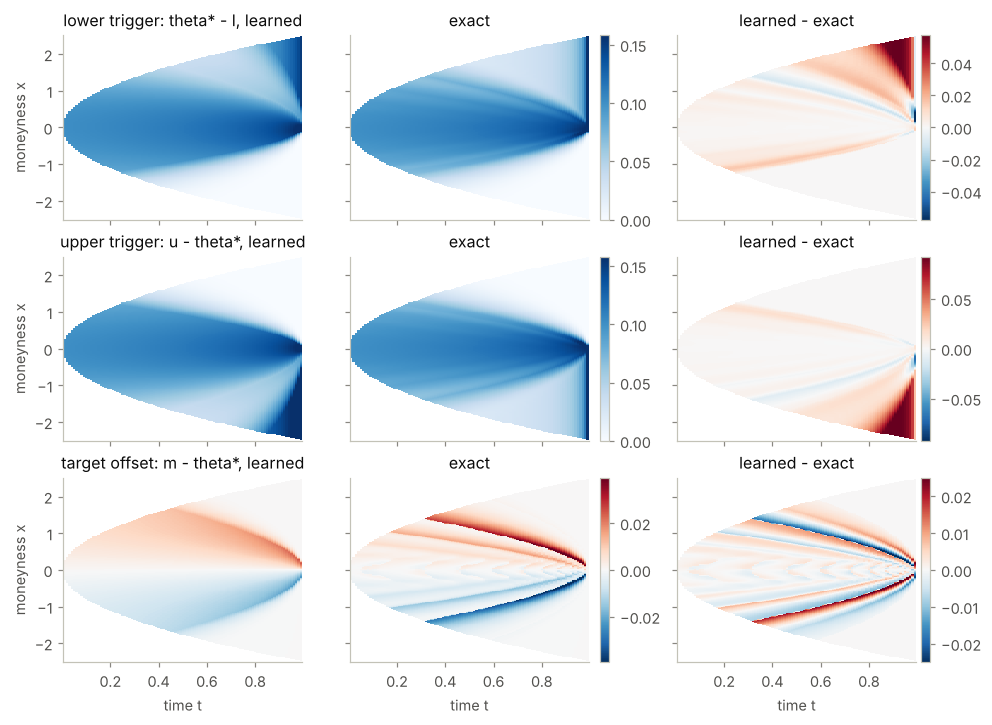

In [16]:
def surfaces(policy_or_dp, xg):
    """Lower trigger, target, upper trigger on a grid of x for every decision date; arrays of shape (len(xg), KD)."""
    if isinstance(policy_or_dp, dict):
        dp = policy_or_dp
        lo = np.stack([np.interp(xg, dp["xs"], dp["lo"][k]) for k in KS], 1)
        m = np.stack([np.interp(xg, dp["xs"], dp["tg"][k]) for k in KS], 1)
        hi = np.stack([np.interp(xg, dp["xs"], dp["hi"][k]) for k in KS], 1)
        return lo, m, hi
    return bands_from_policy(policy_or_dp, np.tile(xg[:, None].astype(np.float32), (1, KD)))

XG = np.linspace(-2.5, 2.5, 201)
TSG = theta_star(KS[None, :], XG[:, None])
GAMG = gamma_of(KS[None, :], XG[:, None])
VISITED = np.abs(XG[:, None]) <= 2.5 * np.sqrt(KS * DT)[None, :]      # the price is within 2.5 standard deviations

def relative(lo, m, hi):
    """Distances of the clipped triggers from theta*, and the target offset."""
    return TSG - np.clip(lo, 0, 1), np.clip(hi, 0, 1) - TSG, m - TSG

S_LEARN = relative(*surfaces(NET, XG))
S_EXACT = relative(*surfaces(DP[LAM], XG))
titles = ["lower trigger: theta* - l", "upper trigger: u - theta*", "target offset: m - theta*"]
fig, axes = plt.subplots(3, 3, figsize=(10.2, 7.4), sharex=True, sharey=True)
tt = KS * DT
for r in range(3):
    a, b = np.where(VISITED, S_LEARN[r], np.nan), np.where(VISITED, S_EXACT[r], np.nan)
    if r < 2:
        vmin, vmax, cmap = 0.0, float(np.nanpercentile(b, 99.5)), "Blues"
    else:
        vmax = float(np.nanpercentile(np.abs(b), 99.5)); vmin, cmap = -vmax, "RdBu_r"
    dmax = max(float(np.nanpercentile(np.abs(a - b), 99.5)), 1e-4)
    for c, (z, lab) in enumerate(((a, "learned"), (b, "exact"), (a - b, "learned - exact"))):
        ax = axes[r, c]
        if c < 2:
            im = ax.pcolormesh(tt, XG, z, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto", rasterized=True)
        else:
            im = ax.pcolormesh(tt, XG, z, cmap="RdBu_r", vmin=-dmax, vmax=dmax, shading="auto", rasterized=True)
        ax.grid(False)
        ax.set_title(f"{titles[r]}, {lab}" if c == 0 else lab)
        if c >= 1:
            fig.colorbar(im, ax=axes[r, :2] if c == 1 else ax, fraction=0.046, pad=0.02)
        if r == 2:
            ax.set_xlabel("time t")
        if c == 0:
            ax.set_ylabel("moneyness x")
fig.savefig(os.path.join(FIG_DIR, "fig_policy_surfaces.png"), bbox_inches="tight")
plt.show(); plt.close(fig)

The same comparison at four dates, as cross-sections. The grey dotted curve is the two-regime rule; the shaded shape at the bottom is the distribution of the price at that date.

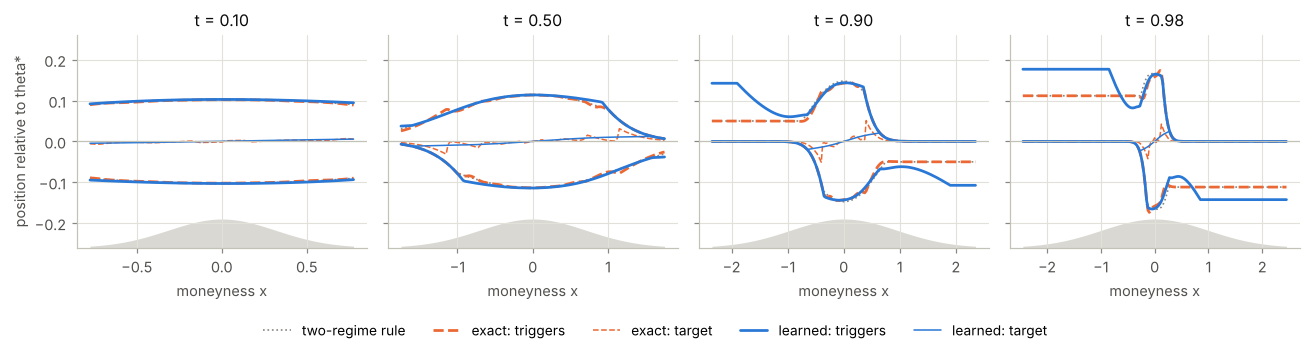

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(12.0, 3.2), sharey=True)
for ax, k in zip(axes, (10, 50, 90, 98)):
    j = k - 1
    w = 2.5 * math.sqrt(k * DT)
    sel = np.abs(XG) <= w
    dens = norm.pdf(XG[sel] / math.sqrt(k * DT))
    ax.fill_between(XG[sel], -0.26, -0.26 + 0.07 * dens / dens.max(), color="#d9d8d2", lw=0, zorder=0)
    b_as = np.maximum(asym_halfwidth(LAM, GAMG[sel, j], True), math.sqrt(LAM / TAUS[j]))
    ax.plot(XG[sel], np.minimum(b_as, 1 - TSG[sel, j]), color=GRAY, lw=1.1, ls=":", label="two-regime rule")
    ax.plot(XG[sel], -np.minimum(b_as, TSG[sel, j]), color=GRAY, lw=1.1, ls=":")
    for S, col, ls, lab in ((S_EXACT, ORANGE, "--", "exact"), (S_LEARN, BLUE, "-", "learned")):
        ax.plot(XG[sel], S[1][sel, j], color=col, ls=ls, lw=1.8, label=f"{lab}: triggers")
        ax.plot(XG[sel], -S[0][sel, j], color=col, ls=ls, lw=1.8)
        ax.plot(XG[sel], S[2][sel, j], color=col, ls=ls, lw=1.0, label=f"{lab}: target")
    ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.set_title(f"t = {k * DT:.2f}"); ax.set_xlabel("moneyness x"); ax.set_ylim(-0.26, 0.26)
axes[0].set_ylabel("position relative to theta*")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5)
finish(fig, "fig_band_slices", rect=(0, 0.09, 1, 1))

**Where they agree.** Before $t=0.9$ the three learned surfaces are within 0.005 to 0.006 of the exact ones over visited states (RMS). Near the money the learned and the exact triggers coincide, and both coincide with the two-regime rule, dotted in the cross-sections.

**Where they differ.**

* Far from the money and late, on the side where the trigger is not cut off by a limit, the exact trigger is flat at the break-even width (0.05 at $t=0.9$, 0.11 at $t=0.98$). The learned trigger is typically wider there, by up to 0.09. This is the dark corner of the difference maps, and the reason why the RMS distance of the triggers rises to 0.02 to 0.03 after $t=0.9$.
* The exact target offset is concentrated on two sharp ridges, one on each side of the money, where $\theta^\star$ comes within about a band-width of the limit 0 or 1, and it points towards that limit. The network has a smooth version of the same pattern, in the right place and with the right sign, at a lower amplitude. Section 20 puts numbers on both statements.
* The exact triggers also carry finer streaks, which the network smooths out. Section 22 shows that the fine structure of the exact band is worth about 0.1% of the cost.

## 20. Law level: did the network find the scaling laws?

Near the money, the half-width $b=(u-\ell)/2$ is regressed on $\Gamma$ over visited states, first as a power law and then in the form $b=A\sqrt\Gamma-B\,\Gamma\sqrt{\Delta t}$ suggested by Section 5, for the learned and the exact policy at each charge level. A pooled fit over the three levels estimates the exponent $\kappa$ of $\lambda$. Far from the money, the distance from $\theta^\star$ to the trigger on the open side is compared with the break-even width $\sqrt{\lambda/\tau}$. Finally the learned target offset is regressed on the exact one. No formula is proposed for the offset. Most of it comes from the limits of the hedge ratio: when $\theta^\star$ is within a band-width of 0 or 1 it can leave the band on one side only, so, conditionally on no further trade, it is expected to move towards the limit, and the best position to hold lies between $\theta^\star$ and the limit.

half-width b against gamma on visited states (t < 0.9, 0.1 < theta* < 0.9)
fit 1: log b = const + slope log(gamma)
fit 2: b = A sqrt(gamma) - B gamma sqrt(dt)
   lambda    policy   slope        A  A/(6 lam)^.25       B  B/0.5826      R2
  1.0e-04   learned   0.234   0.1723          1.101   0.802      1.38  0.9669
  1.0e-04     exact   0.288   0.1593          1.018   0.657      1.13  0.9959
  2.5e-04   learned   0.311   0.2106          1.070   0.761      1.31  0.9664
  2.5e-04     exact   0.356   0.1982          1.007   0.623      1.07  0.9941
  5.0e-04   learned   0.374   0.2398          1.025   0.637      1.09  0.9768
  5.0e-04     exact   0.393   0.2338          0.999   0.586      1.01  0.9924

the same two fits for the other seeds at the main charge level:
   seed 2: slope 0.319, A/(6 lam)^.25 = 1.058, B/0.5826 = 1.25, R2 = 0.9758
   seed 3: slope 0.305, A/(6 lam)^.25 = 1.076, B/0.5826 = 1.32, R2 = 0.9516

pooled over the three charge levels: b = a lam^kappa sqrt(gamma) - B gamma sq

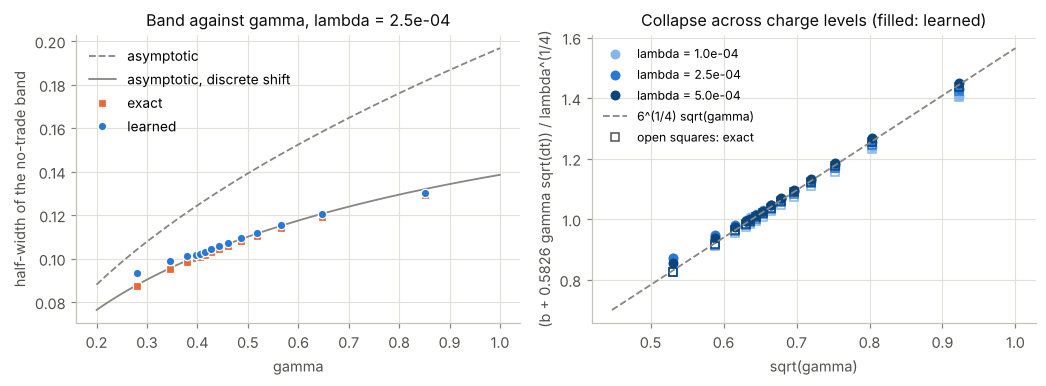

In [18]:
INNER = (0.1, 0.9)                                     # states where the band is not cut off by the limits 0 and 1

def band_sample(lo, hi, max_paths=20000):
    """Half-width and gamma on visited states with t < 0.9 and theta* inside INNER."""
    r = slice(0, min(max_paths, lo.shape[0]))
    ts, g = TS_EVAL[r][:, EARLY], GAM_EVAL[r][:, EARLY]
    b = 0.5 * (np.clip(hi[r][:, EARLY], 0, 1) - np.clip(lo[r][:, EARLY], 0, 1))
    ok = (ts > INNER[0]) & (ts < INNER[1])
    return b[ok].astype(np.float64), g[ok].astype(np.float64)

def fit_laws(b, g, lam):
    slope = np.polyfit(np.log(g), np.log(np.maximum(b, 1e-6)), 1)[0]
    D = np.stack([np.sqrt(g), -g * SD], 1)
    (A, B), *_ = np.linalg.lstsq(D, b, rcond=None)
    r2 = 1 - np.sum((b - D @ np.array([A, B])) ** 2) / np.sum((b - b.mean()) ** 2)
    return dict(slope=slope, A=A, B=B, r2=r2, A_ratio=A / (6 * lam) ** 0.25, B_ratio=B / BGK)

LAWS, SAMPLES = {}, {}
print("half-width b against gamma on visited states (t < 0.9, 0.1 < theta* < 0.9)")
print("fit 1: log b = const + slope log(gamma)")
print("fit 2: b = A sqrt(gamma) - B gamma sqrt(dt)")
print(f"{'lambda':>9s} {'policy':>9s} {'slope':>7s} {'A':>8s} {'A/(6 lam)^.25':>14s} {'B':>7s} {'B/0.5826':>9s} {'R2':>7s}")
for lam_ in LAMS:
    net_ = NETS[(lam_, "replay", SEED0)]
    lo_, m_, hi_ = bands_from_policy(net_, X_EVAL[:20000])
    SAMPLES[(lam_, "learned")] = band_sample(lo_, hi_)
    lo_, m_, hi_ = bands_dp(DP[lam_], X_EVAL[:20000])
    SAMPLES[(lam_, "exact")] = band_sample(lo_, hi_)
    for who in ("learned", "exact"):
        f = fit_laws(*SAMPLES[(lam_, who)], lam_)
        LAWS[(lam_, who)] = f
        print(f"{lam_:9.1e} {who:>9s} {f['slope']:7.3f} {f['A']:8.4f} {f['A_ratio']:14.3f} {f['B']:7.3f} {f['B_ratio']:9.2f} {f['r2']:7.4f}")

print("\nthe same two fits for the other seeds at the main charge level:")
for seed_ in SEEDS[1:]:
    lo_, m_, hi_ = bands_from_policy(NETS[(LAM, "replay", seed_)], X_EVAL[:20000])
    f = fit_laws(*band_sample(lo_, hi_), LAM)
    print(f"   seed {seed_}: slope {f['slope']:.3f}, A/(6 lam)^.25 = {f['A_ratio']:.3f}, B/0.5826 = {f['B_ratio']:.2f}, R2 = {f['r2']:.4f}")

def fit_kappa(who):
    """Pooled fit b = a lam^kappa sqrt(gamma) - B gamma sqrt(dt) over the three charge levels."""
    bs = np.concatenate([SAMPLES[(l, who)][0] for l in LAMS])
    gs = np.concatenate([SAMPLES[(l, who)][1] for l in LAMS])
    ls = np.concatenate([np.full(len(SAMPLES[(l, who)][0]), l) for l in LAMS])
    best = None
    for kappa in np.arange(0.15, 0.3501, 0.0025):
        D = np.stack([ls ** kappa * np.sqrt(gs), -gs * SD], 1)
        coef, *_ = np.linalg.lstsq(D, bs, rcond=None)
        sse = float(np.sum((bs - D @ coef) ** 2))
        if best is None or sse < best[0]:
            best = (sse, kappa, coef)
    return best[1], best[2][0], best[2][1]

KAPPA = {who: fit_kappa(who) for who in ("learned", "exact")}
print("\npooled over the three charge levels: b = a lam^kappa sqrt(gamma) - B gamma sqrt(dt)")
print(f"{'policy':>9s} {'kappa':>7s} {'a':>7s} {'B':>7s}")
for who in ("learned", "exact"):
    print(f"{who:>9s} {KAPPA[who][0]:7.3f} {KAPPA[who][1]:7.3f} {KAPPA[who][2]:7.3f}")
print(f"{'theory':>9s} {0.25:7.3f} {6 ** 0.25:7.3f} {BGK:7.3f}")

def far_sample(lo, hi, lam, max_paths=20000):
    """Distance from theta* to the trigger on the open side, on visited states where gamma is negligible."""
    r = slice(0, min(max_paths, lo.shape[0]))
    ts, g, x = TS_EVAL[r], GAM_EVAL[r], X_EVAL[r]
    dist = np.where(x > 0, ts - np.clip(lo[r], 0, 1), np.clip(hi[r], 0, 1) - ts)
    room = np.where(x > 0, ts, 1 - ts)                 # the trigger cannot be further than the limit 0 or 1
    be = np.broadcast_to(break_even(lam), ts.shape)
    ok = (asym_halfwidth(lam, g, True) < 0.25 * be) & (room > 1.5 * be)
    tau = np.broadcast_to(TAUS[None, :], ts.shape)
    return dist[ok].astype(np.float64), tau[ok].astype(np.float64)

FAR = {}
print("\nfar from the money (gamma negligible): distance from theta* to the trigger,")
print("compared with the break-even width sqrt(lam / tau); theory: ratio 1, slope -0.5")
print(f"{'lambda':>9s} {'policy':>9s} {'states':>8s} {'median ratio to break-even':>27s} {'slope in log tau':>17s}")
for lam_ in LAMS:
    net_ = NETS[(lam_, "replay", SEED0)]
    for who, (lo_, m_, hi_) in (("learned", bands_from_policy(net_, X_EVAL[:20000])), ("exact", bands_dp(DP[lam_], X_EVAL[:20000]))):
        dist, tau = far_sample(lo_, hi_, lam_)
        slope = np.polyfit(np.log(tau), np.log(np.maximum(dist, 1e-6)), 1)[0]
        FAR[(lam_, who)] = dict(n=len(dist), ratio=float(np.median(dist / np.sqrt(lam_ / tau))), slope=slope)
        print(f"{lam_:9.1e} {who:>9s} {len(dist):8d} {FAR[(lam_, who)]['ratio']:27.3f} {slope:17.3f}")

# target offset: how much of the exact offset did the network recover?
r_ = slice(0, 20000)
off_exact = (EXACT["m"][r_] - TS_EVAL[r_])[:, EARLY].reshape(-1).astype(np.float64)
off_learn = (LEARN["m"][r_] - TS_EVAL[r_])[:, EARLY].reshape(-1).astype(np.float64)
slope_off = float(off_learn @ off_exact / (off_exact @ off_exact))
OFFSET = dict(slope=slope_off, corr=float(np.corrcoef(off_learn, off_exact)[0, 1]),
              rms_exact=float(np.sqrt(np.mean(off_exact ** 2))), rms_learn=float(np.sqrt(np.mean(off_learn ** 2))),
              at_limit=float(np.mean((EXACT["m"][r_][:, EARLY] < 1e-3) | (EXACT["m"][r_][:, EARLY] > 1 - 1e-3))))
print("\ntarget offset m - theta* on visited states, t < 0.9")
print(f"   RMS size: exact {OFFSET['rms_exact']:.4f}, learned {OFFSET['rms_learn']:.4f}")
print(f"   learned regressed on exact: slope {OFFSET['slope']:.2f}, correlation {OFFSET['corr']:.2f}")
print(f"   share of visited states where the exact target is a limit (0 or 1): {100 * OFFSET['at_limit']:.0f}%")
ts_ = TS_EVAL[r_][:, EARLY].reshape(-1)
room_ = np.minimum(ts_, 1 - ts_) / two_regime_halfwidth(LAM, GAM_EVAL[r_])[:, EARLY].reshape(-1)
print("   by distance from the nearer limit, in band-widths:")
print(f"   {'':22s} {'share of states':>16s} {'RMS exact':>10s} {'RMS learned':>12s} {'points to the limit':>20s}")
for lab_, mask_ in (("more than 2", room_ > 2), ("between 1 and 2", (room_ > 1) & (room_ <= 2)), ("less than 1", room_ <= 1)):
    to_limit = np.mean((np.sign(off_exact) == np.sign(ts_ - 0.5))[mask_ & (np.abs(off_exact) > 1e-4)])
    print(f"   {lab_:22s} {100 * mask_.mean():15.0f}% {np.sqrt(np.mean(off_exact[mask_] ** 2)):10.4f} "
          f"{np.sqrt(np.mean(off_learn[mask_] ** 2)):12.4f} {100 * to_limit:19.0f}%")

def binned(g, b, nb=14):
    q = np.quantile(g, np.linspace(0, 1, nb + 1))
    idx = np.clip(np.searchsorted(q, g, side="right") - 1, 0, nb - 1)
    return np.array([g[idx == i].mean() for i in range(nb)]), np.array([b[idx == i].mean() for i in range(nb)])

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.6))
gg = np.linspace(0.2, 1.0, 100)
ax[0].plot(gg, (6 * LAM) ** 0.25 * np.sqrt(gg), color=GRAY, ls="--", lw=1.2, label="asymptotic")
ax[0].plot(gg, asym_halfwidth(LAM, gg, True), color=GRAY, ls="-", lw=1.2, label="asymptotic, discrete shift")
for who, col, mk in (("exact", ORANGE, "s"), ("learned", BLUE, "o")):
    x_, y_ = binned(SAMPLES[(LAM, who)][1], SAMPLES[(LAM, who)][0])
    ax[0].plot(x_, y_, mk, color=col, ms=5.5, mec="white", mew=0.8, label=who)
ax[0].set_xlabel("gamma"); ax[0].set_ylabel("half-width of the no-trade band"); ax[0].set_title(f"Band against gamma, lambda = {LAM:.1e}")
ax[0].legend()
shades = ["#85b7eb", "#2a78d6", "#0c447c"]
for lam_, col in zip(LAMS, shades):
    for who, mk, fill in (("exact", "s", "none"), ("learned", "o", col)):
        b_, g_ = SAMPLES[(lam_, who)]
        x_, y_ = binned(g_, (b_ + BGK * g_ * SD) / lam_ ** 0.25)
        ax[1].plot(np.sqrt(x_), y_, mk, color=col, mfc=fill, ms=5.5, mew=1.0,
                   label=f"lambda = {lam_:.1e}" if who == "learned" else None)
sq = np.sqrt(gg)
ax[1].plot(sq, 6 ** 0.25 * sq, color=GRAY, ls="--", lw=1.2, label="6^(1/4) sqrt(gamma)")
ax[1].plot([], [], "s", color=INK2, mfc="none", ms=5.5, label="open squares: exact")
ax[1].set_xlabel("sqrt(gamma)"); ax[1].set_ylabel("(b + 0.5826 gamma sqrt(dt)) / lambda^(1/4)")
ax[1].set_title("Collapse across charge levels (filled: learned)"); ax[1].legend(fontsize=8, loc="upper left")
finish(fig, "fig_scaling_laws")

**Near the money.** Both policies follow $b=A\sqrt\Gamma-B\,\Gamma\sqrt{\Delta t}$, with $R^2=0.99$ for the exact policy and $0.97$ for the learned one. For the exact policy the fitted $A$ is within 2% of $(6\lambda)^{1/4}$ at the three charge levels and the fitted $B$ within 13% of the constant of Broadie, Glasserman and Kou. For the learned policy $A$ is 2% to 10% too high and $B$ 9% to 38% too high; the two errors partly offset each other. Pooled over the charge levels, the exponent of $\lambda$ is 0.240 for the learned policy and 0.255 for the exact one, against $\tfrac14$. The three networks were trained separately and none has $\lambda$ as an input, so this exponent is a property of three independent solutions.

**Far from the money.** The exact trigger is the break-even width to three digits: ratio 1.000 and slope $-0.50$ in $\log\tau$ at the three charge levels. The learned trigger is 36% to 63% wider, with a slope of $-0.27$ to $-0.36$. The network has the direction of this regime, not its law.

**Target.** The learned offset has two thirds of the amplitude of the exact one (regression slope 0.67) and a correlation of 0.81 with it. In both policies the offset is small where $\theta^\star$ is more than two band-widths away from the limits 0 and 1 (RMS 0.003), and five times larger within one band-width of a limit (0.015 exact, 0.011 learned), where it always points to the limit.

## 21. Decision level: where the remaining cost comes from

The performance-difference identity of Section 7 turns the gap to the optimum into a sum of one-step regrets, each computed from the exact action-value function. The first line of each report compares that sum with the cost difference measured directly on the evaluation paths; the two are estimates of the same number. The regret is then split by kind of error, by time and by moneyness $|d|$, for the learned policy and for two formulas. In the figure the horizontal scales of the three panels differ. The last line of the output applies the same decomposition to the exact policy as simulated; its regret would be zero without interpolation between grid nodes, and it gives the resolution of the analysis.

learned policy
   cost above exact on the paths 3.58e-05 +- 8.6e-07 | sum of one-step regrets 3.68e-05
   by kind:      unneeded 11%, missed 42%, target 46%
   by time:      0-0.25: 2%, 0.25-0.5: 10%, 0.5-0.75: 31%, 0.75-0.9: 36%, 0.9-1: 21%
   by moneyness: |d|<0.5: 2%, 0.5-1.5: 26%, |d|>1.5: 73%
two-regime rule
   cost above exact on the paths 4.68e-05 +- 9.7e-07 | sum of one-step regrets 4.80e-05
   by kind:      unneeded 4%, missed 8%, target 89%
   by time:      0-0.25: 2%, 0.25-0.5: 14%, 0.5-0.75: 36%, 0.75-0.9: 30%, 0.9-1: 18%
   by moneyness: |d|<0.5: 3%, 0.5-1.5: 30%, |d|>1.5: 67%
asymptotic band, discrete shift
   cost above exact on the paths 4.35e-04 +- 1.4e-06 | sum of one-step regrets 4.36e-04
   by kind:      unneeded 89%, missed 1%, target 10%
   by time:      0-0.25: 0%, 0.25-0.5: 2%, 0.5-0.75: 6%, 0.75-0.9: 17%, 0.9-1: 75%
   by moneyness: |d|<0.5: 0%, 0.5-1.5: 3%, |d|>1.5: 96%
exact policy as simulated: sum of one-step regrets 8.37e-07, 0.019% of the optimal cost


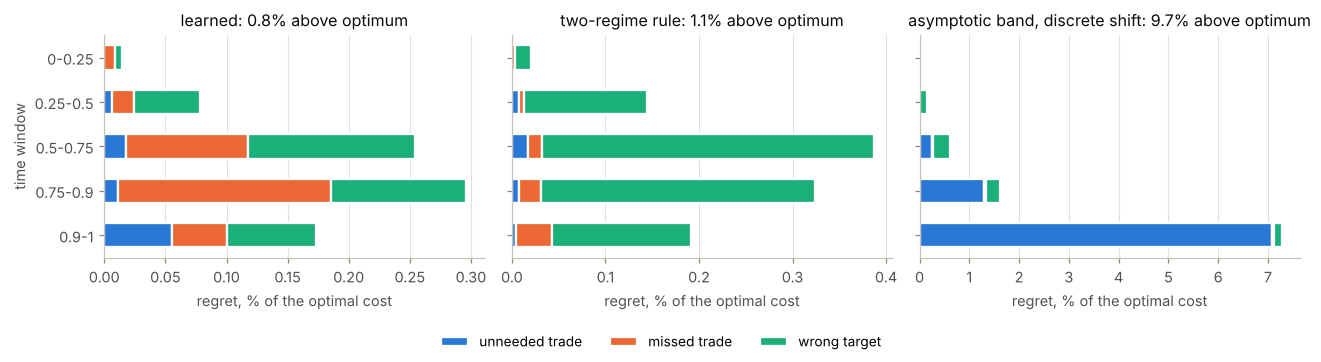

In [19]:
def interp_C(C, dp, x, th):
    """Bilinear interpolation of the exact holding cost C_k(x, theta)."""
    nx, nth = C.shape
    fx = np.clip((x - dp["xs"][0]) / dp["dx"], 0, nx - 1.000001); i0 = fx.astype(np.int64); wx = fx - i0
    ft = np.clip(th / dp["dth"], 0, nth - 1.000001); j0 = ft.astype(np.int64); wt = ft - j0
    return ((1 - wx) * (1 - wt) * C[i0, j0] + wx * (1 - wt) * C[i0 + 1, j0]
            + (1 - wx) * wt * C[i0, j0 + 1] + wx * wt * C[i0 + 1, j0 + 1])

def interp_Cmin(C, im, dp, x, window=50, chunk=32768):
    """min over theta of the same interpolated surface, searched around the two neighbouring grid minimisers.

    Interpolating the grid minima in x instead would understate the minimum between nodes and bias every
    regret upward; taking the minimum of the interpolated surface keeps Q* and V* consistent.
    """
    nx, nth = C.shape
    out = np.empty(len(x))
    offs = np.arange(-window, window + 1)[None, :]
    for s in range(0, len(x), chunk):
        xx = x[s:s + chunk]
        fx = np.clip((xx - dp["xs"][0]) / dp["dx"], 0, nx - 1.000001); i0 = fx.astype(np.int64); wx = (fx - i0)[:, None]
        j = np.clip(((im[i0] + im[i0 + 1]) // 2)[:, None] + offs, 0, nth - 1)
        out[s:s + chunk] = ((1 - wx) * C[i0[:, None], j] + wx * C[i0[:, None] + 1, j]).min(axis=1)
    return out

def regret_decomposition(dp, lam, pol):
    """Split J(policy) - J* into three kinds of one-step regret, per (path, date).

    unneeded: the policy trades where the exact rule holds; missed: it holds where the exact rule trades;
    target: it trades to a position that is not the exact target. Their sum is Q*(s, a) - V*(s).
    """
    shape = X_EVAL.shape
    unneeded = np.zeros(shape, dtype=np.float32); missed = np.zeros(shape, dtype=np.float32); target = np.zeros(shape, dtype=np.float32)
    for j in range(KD):
        k = j + 1
        C = dp["C"][k]
        x = X_EVAL[:, j].astype(np.float64)
        y = pol["Y"][:, j]
        c_hold = interp_C(C, dp, x, pol["TPRE"][:, j].astype(np.float64))
        c_min = interp_Cmin(C, dp["im"][k], dp, x)
        c_tgt = interp_C(C, dp, x, np.clip(pol["m"][:, j].astype(np.float64), 0, 1))
        exact_trades = c_hold > lam + c_min
        unneeded[:, j] = np.where(y & ~exact_trades, lam + c_min - c_hold, 0.0)
        missed[:, j] = np.where(~y & exact_trades, c_hold - lam - c_min, 0.0)
        target[:, j] = np.where(y, np.maximum(c_tgt - c_min, 0.0), 0.0)
    return dict(unneeded=unneeded, missed=missed, target=target)

T_EDGES = [0.0, 0.25, 0.5, 0.75, 0.9, 1.0001]
T_LABELS = ["0-0.25", "0.25-0.5", "0.5-0.75", "0.75-0.9", "0.9-1"]
D_EDGES = [0.0, 0.5, 1.5, np.inf]
D_LABELS = ["|d|<0.5", "0.5-1.5", "|d|>1.5"]
ABS_D = np.abs(X_EVAL / np.sqrt(TAUS)[None, :])

def regret_report(name, pol, lam=LAM):
    reg = regret_decomposition(DP[lam], lam, pol)
    total = sum(v.sum(1, dtype=np.float64).mean() for v in reg.values())
    d_ = pol["cost"] - REF[lam]["exact optimum (DP)"]["cost"]
    gap, gap_se = d_.mean(), d_.std() / math.sqrt(len(d_))
    by_time = {key: np.array([v[:, (KS * DT >= a) & (KS * DT < b)].sum(1, dtype=np.float64).mean()
                              for a, b in zip(T_EDGES[:-1], T_EDGES[1:])]) for key, v in reg.items()}
    by_d = np.array([sum(np.where((ABS_D >= a) & (ABS_D < b), v, 0).sum(1, dtype=np.float64).mean() for v in reg.values())
                     for a, b in zip(D_EDGES[:-1], D_EDGES[1:])])
    print(f"{name}")
    print(f"   cost above exact on the paths {gap:.2e} +- {gap_se:.1e} | sum of one-step regrets {total:.2e}")
    print("   by kind:      " + ", ".join(f"{key} {100 * v.sum() / total:.0f}%" for key, v in by_time.items()))
    print("   by time:      " + ", ".join(f"{lab}: {100 * sum(v[i] for v in by_time.values()) / total:.0f}%" for i, lab in enumerate(T_LABELS)))
    print("   by moneyness: " + ", ".join(f"{lab}: {100 * v / total:.0f}%" for lab, v in zip(D_LABELS, by_d)))
    return dict(total=total, gap=gap, by_time=by_time, by_d=by_d)

lo_, m_, hi_ = bands_symmetric(TS_EVAL, asym_halfwidth(LAM, GAM_EVAL, True))
ASYM = run_bands(X_EVAL, TS_EVAL, lo_, m_, hi_, LAM, keep=True)
ASYM.update(lo=lo_, m=m_, hi=hi_)
del lo_, m_, hi_
lo_, m_, hi_ = bands_symmetric(TS_EVAL, two_regime_halfwidth(LAM, GAM_EVAL))
TWO = run_bands(X_EVAL, TS_EVAL, lo_, m_, hi_, LAM, keep=True)
TWO.update(lo=lo_, m=m_, hi=hi_)
del lo_, m_, hi_
REG = {"learned": regret_report("learned policy", LEARN),
       "two-regime rule": regret_report("two-regime rule", TWO),
       "asymptotic band, discrete shift": regret_report("asymptotic band, discrete shift", ASYM)}
r0_ = regret_decomposition(DP[LAM], LAM, EXACT)
REG_EXACT = sum(v.sum(1, dtype=np.float64).mean() for v in r0_.values())
del r0_
print(f"exact policy as simulated: sum of one-step regrets {REG_EXACT:.2e}, "
      f"{100 * REG_EXACT / DP[LAM]['J0']:.3f}% of the optimal cost")

fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.3), sharey=True)
jstar = REF[LAM]["exact optimum (DP)"]["cost"].mean()
for ax, (name, r) in zip(axes, REG.items()):
    left = np.zeros(len(T_LABELS))
    for key, col, lab in (("unneeded", BLUE, "unneeded trade"), ("missed", ORANGE, "missed trade"), ("target", AQUA, "wrong target")):
        v = 100 * r["by_time"][key] / jstar
        ax.barh(T_LABELS, v, left=left, color=col, height=0.55, label=lab, edgecolor="white", linewidth=1.5)
        left += v
    ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_title(f"{name}: {100 * r['total'] / jstar:.1f}% above optimum"); ax.set_xlabel("regret, % of the optimal cost")
axes[0].set_ylabel("time window")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3)
finish(fig, "fig_regret", rect=(0, 0.09, 1, 1))

**The decomposition checks itself.** In each report the sum of one-step regrets and the cost difference measured on the paths agree to about one standard error. The sums are larger by about $10^{-6}$ in all three, and the last line shows why: the exact policy as simulated carries a regret of $8\times10^{-7}$, 0.02% of the cost, from interpolation between grid nodes. That is the resolution of this analysis.

**The near-the-money formula** loses 9.7%. Of that, 89% is trades that the exact rule would not make, 96% is at $|d|>1.5$ and 75% in the last tenth of the life. Where gamma vanishes the formula sends the band to zero, and the rule keeps paying the charge to remove mis-hedges that no longer matter. This observation is what led to the break-even floor of Section 5.

**The two-regime rule** loses 1.04%, and 89% of that is trades to the wrong target. It trades when the exact rule does, but to $\theta^\star$.

**The learned policy** loses 0.79%, split between trades to the wrong target (46%) and missed trades (42%). Of its loss, 73% is at $|d|>1.5$ and 57% after $t=0.75$. The missed trades are consistent with the band that is too wide far from the money (Section 20); the decomposition was not broken down further to confirm it.

## 22. Component level: which features of the policy matter

Features are removed one at a time and the policy is re-priced on the same paths. The right-hand column applies the same operation to the exact policy, which shows how much each feature is worth when it is exactly right. The last row goes the other way: the band is replaced by the closed-form two-regime band and the policy keeps its own target, clipped into that band. Nothing is fitted in that row.

In [20]:
def ablate(pol, lam, law):
    """Remove learned features one at a time and price the result on the evaluation paths."""
    lo, m, hi = pol["lo"], pol["m"], pol["hi"]
    wide = np.maximum(TS_EVAL - np.clip(lo, 0, 1), np.clip(hi, 0, 1) - TS_EVAL)   # the larger of the two distances from theta*
    out = {"as is": run_bands(X_EVAL, TS_EVAL, lo, m, hi, lam)}
    out["target moved to theta*"] = run_bands(X_EVAL, TS_EVAL, lo, TS_EVAL, hi, lam)
    out["and band made symmetric around theta*"] = run_bands(X_EVAL, TS_EVAL, *bands_symmetric(TS_EVAL, wide), lam)
    b_law = law["A"] * np.sqrt(GAM_EVAL) - law["B"] * GAM_EVAL * SD
    out["two-parameter law fitted to it"] = run_bands(X_EVAL, TS_EVAL, *bands_symmetric(TS_EVAL, b_law), lam)
    out["the same law with the break-even floor"] = run_bands(X_EVAL, TS_EVAL, *bands_symmetric(TS_EVAL, np.maximum(b_law, break_even(lam))), lam)
    b2 = two_regime_halfwidth(lam, GAM_EVAL)            # the closed-form band, with the policy's own target kept inside it
    out["two-regime band, its own target kept"] = run_bands(X_EVAL, TS_EVAL, TS_EVAL - b2, np.clip(m, TS_EVAL - b2, TS_EVAL + b2), TS_EVAL + b2, lam)
    return out

ABL = {"learned": ablate(LEARN, LAM, LAWS[(LAM, "learned")]), "exact": ablate(EXACT, LAM, LAWS[(LAM, "exact")])}
ref_ = REF[LAM]["exact optimum (DP)"]
print("cost above the exact optimum after removing features of the policy (same paths)")
print(f"{'':50s} {'learned':>17s} {'exact':>17s}")
for key in ABL["learned"]:
    a, b = summarise(ABL["learned"][key], ref_), summarise(ABL["exact"][key], ref_)
    print(f"{key:50s} {a['gap_pct']:+8.2f}% +- {a['gap_se']:.2f} {b['gap_pct']:+8.2f}% +- {b['gap_se']:.2f}")
for name in (TWO_KEY, "asymptotic band, discrete shift"):
    s = summarise(REF[LAM][name], ref_)
    print(f"{'reference: ' + name:60s} {s['gap_pct']:+8.2f}% +- {s['gap_se']:.2f}")

print()
print("the last row for the other networks: the two-regime band with the network's own target")
HYBRID = {(LAM, SEED0): summarise(ABL["learned"]["two-regime band, its own target kept"], ref_)["gap_pct"]}
for lam_, seed_ in [(LAM, s_) for s_ in SEEDS[1:]] + [(l_, SEED0) for l_ in LAMS if l_ != LAM]:
    _, m_s, _ = bands_from_policy(NETS[(lam_, "replay", seed_)], X_EVAL)
    b2_ = two_regime_halfwidth(lam_, GAM_EVAL)
    r_ = run_bands(X_EVAL, TS_EVAL, TS_EVAL - b2_, np.clip(m_s, TS_EVAL - b2_, TS_EVAL + b2_), TS_EVAL + b2_, lam_)
    ref_l = REF[lam_]["exact optimum (DP)"]
    HYBRID[(lam_, seed_)] = summarise(r_, ref_l)["gap_pct"]
    print(f"   lambda {lam_:.1e}, seed {seed_}: {HYBRID[(lam_, seed_)]:+.2f}%   (network as is "
          f"{summarise(RES[(lam_, 'replay', seed_)], ref_l)['gap_pct']:+.2f}%, two-regime rule {summarise(REF[lam_][TWO_KEY], ref_l)['gap_pct']:+.2f}%)")
    del m_s, b2_, r_

cost above the exact optimum after removing features of the policy (same paths)
                                                             learned             exact
as is                                                 +0.79% +- 0.02    +0.00% +- 0.00
target moved to theta*                                +1.41% +- 0.02    +1.07% +- 0.02
and band made symmetric around theta*                 +1.55% +- 0.02    +1.08% +- 0.02
two-parameter law fitted to it                        +9.53% +- 0.03    +9.65% +- 0.03
the same law with the break-even floor                +1.07% +- 0.02    +1.04% +- 0.02
two-regime band, its own target kept                  +0.47% +- 0.02    +0.11% +- 0.01
reference: two-regime rule (near / break-even)                  +1.04% +- 0.02
reference: asymptotic band, discrete shift                      +9.65% +- 0.03

the last row for the other networks: the two-regime band with the network's own target
   lambda 2.5e-04, seed 2: +0.48%   (network as is +1.02%, two-re

**The exact policy.** Read the right-hand column first. Moving the exact target to $\theta^\star$ costs 1.07%, and making the band symmetric as well costs nothing more (1.08%). Putting the exact target inside the closed-form two-regime band costs 0.11%. So the exact policy is, to a tenth of a percent of the cost, the two-regime band plus a target offset, and the offset is worth one percent. The resolution of these numbers is a few hundredths of a percent: the standard errors are 0.01 to 0.02 and the benchmark error 0.02.

**The learned policy** has both ingredients in part. Its target offset is worth 0.6 points: 0.79% with it, 1.41% without. Its band, reduced to the fitted near-the-money law, loses 9.5% like the formula, and recovers with the break-even floor (1.07%).

**The combination.** The last row takes from each side what it has right. The closed-form band with the learned target is 0.47% above the optimum, against 0.79% for the network and 1.04% for the formula. The same holds for every network trained here: 0.48% and 0.48% for the two other seeds, 0.43% and 0.63% at the two other charge levels, each time below both the network and the formula. The errors of the two sit in different places, as the regret analysis said, and they are separable.

## 23. Representation level: what the hidden layer encodes

The triggers are read linearly from the last hidden layer (64 units). The first table asks which quantities can be decoded linearly from that layer, on visited states held out from the fit. Two controls calibrate the answer: the two raw inputs, and the hidden layer of a network with the same architecture that was never trained. A random hidden layer of 64 smooth units is already a rich basis, so the comparison of interest is trained against untrained. The second table gives the principal components of the trained layer and what they correlate with.

In [21]:
def hidden_states(net, X):
    with torch.no_grad():
        h, d = net.hidden(torch.as_tensor(X, dtype=torch.float32, device=DEVICE), SQTAU_T)
    return h.cpu().numpy().reshape(-1, h.shape[-1]), d.cpu().numpy().reshape(-1)

PROBE_PATHS = 2000
Xp = X_EVAL[:PROBE_PATHS]
H_TRAINED, D_P = hidden_states(NET, Xp)
torch.manual_seed(999)
NET_RANDOM = BandNet().to(DEVICE)                      # same architecture, never trained: the control
H_RANDOM, _ = hidden_states(NET_RANDOM, Xp)
F_INPUT = np.stack([D_P / 2.0, np.tile(np.sqrt(TAUS), PROBE_PATHS)], 1)
half_exact = 0.5 * (np.clip(EXACT["hi"][:PROBE_PATHS], 0, 1) - np.clip(EXACT["lo"][:PROBE_PATHS], 0, 1))
TARGETS = {
    "sqrt(gamma)": np.sqrt(GAM_EVAL[:PROBE_PATHS]).reshape(-1),
    "theta*": TS_EVAL[:PROBE_PATHS].reshape(-1),
    "sqrt(tau)": np.tile(np.sqrt(TAUS), PROBE_PATHS),
    "exact half-width": half_exact.reshape(-1),
    "exact target offset": (EXACT["m"][:PROBE_PATHS] - TS_EVAL[:PROBE_PATHS]).reshape(-1),
}
rng_ = np.random.default_rng(0)
perm = rng_.permutation(H_TRAINED.shape[0])
TR, TE = perm[: int(0.7 * len(perm))], perm[int(0.7 * len(perm)):]

def linear_probe(Fm, y, ridge=1e-4):
    """Ridge regression of y on standardised features; returns test R2 and the direction in feature space."""
    mu, sd = Fm[TR].mean(0), Fm[TR].std(0) + 1e-8
    Z = (Fm - mu) / sd
    A = Z[TR].T @ Z[TR] + ridge * len(TR) * np.eye(Z.shape[1])
    w = np.linalg.solve(A, Z[TR].T @ (y[TR] - y[TR].mean()))
    pred = Z[TE] @ w + y[TR].mean()
    r2 = 1 - np.sum((y[TE] - pred) ** 2) / np.sum((y[TE] - y[TE].mean()) ** 2)
    return r2, w / sd

PROBES = {}
print(f"linear probes on {H_TRAINED.shape[0]} visited states: test R2 of a linear read-out")
print(f"{'target':22s} {'raw inputs (2)':>15s} {'untrained hidden (64)':>22s} {'trained hidden (64)':>20s}")
for name, y in TARGETS.items():
    y = y.astype(np.float64)
    r_in, _ = linear_probe(F_INPUT.astype(np.float64), y)
    r_rand, _ = linear_probe(H_RANDOM.astype(np.float64), y)
    r_tr, w = linear_probe(H_TRAINED.astype(np.float64), y)
    PROBES[name] = dict(inputs=r_in, random=r_rand, trained=r_tr, direction=w)
    print(f"{name:22s} {r_in:15.3f} {r_rand:22.3f} {r_tr:20.3f}")

Hc = H_TRAINED.astype(np.float64) - H_TRAINED.mean(0)
_, sv, Vt = np.linalg.svd(Hc[TR][:20000], full_matrices=False)
evr = sv ** 2 / np.sum(sv ** 2)
scores = Hc @ Vt[:3].T
print("\nprincipal components of the trained hidden layer, share of variance:")
print("   " + ", ".join(f"PC{i + 1} {100 * evr[i]:.1f}%" for i in range(5))
      + f" | participation ratio {np.sum(sv ** 2) ** 2 / np.sum(sv ** 4):.2f}")
print(f"{'correlation with':18s} " + " ".join(f"{n:>14s}" for n in ("sqrt(gamma)", "theta* - 1/2", "sqrt(tau)")))
for i in range(3):
    cs = [np.corrcoef(scores[:, i], t)[0, 1] for t in (TARGETS["sqrt(gamma)"], TARGETS["theta*"] - 0.5, TARGETS["sqrt(tau)"])]
    print(f"{'PC' + str(i + 1):18s} " + " ".join(f"{c:14.2f}" for c in cs))

linear probes on 198000 visited states: test R2 of a linear read-out
target                  raw inputs (2)  untrained hidden (64)  trained hidden (64)
sqrt(gamma)                      0.074                  0.962                0.994
theta*                           0.772                  0.993                1.000
sqrt(tau)                        1.000                  1.000                1.000
exact half-width                 0.112                  0.926                0.988
exact target offset              0.153                  0.555                0.645

principal components of the trained hidden layer, share of variance:
   PC1 62.6%, PC2 31.3%, PC3 3.2%, PC4 2.1%, PC5 0.6% | participation ratio 2.03
correlation with      sqrt(gamma)   theta* - 1/2      sqrt(tau)
PC1                         -0.64           0.40          -0.54
PC2                         -0.42          -0.74          -0.32
PC3                         -0.02          -0.52           0.04


A probe shows that a quantity *can* be read from the layer, not that the policy *uses* it. The causal test erases one quantity linearly from the hidden layer, so that no linear read-out can depend on it any more, recomputes the policy from the edited layer, and prices it. The triggers and the target are linear read-outs of this layer followed by a monotone squashing, so the edit removes exactly the linear contribution of that quantity to the policy. The erasure is fitted and applied on dates with $t<0.9$, and the edited policies are priced on the first 16,384 evaluation paths.

Two columns say what the edit did to the layer: the $R^2$ of a linear read-out of the erased quantity afterwards, which is zero by construction, and the $R^2$ of a quadratic read-out of the first six principal components. The second column is the caveat. A layer that embeds two inputs non-linearly keeps every function of them in some non-linear form, so linear erasure tests what the *linear read-out* relies on, not what the layer contains.

In [22]:
EARLY_ROWS = np.tile(EARLY, PROBE_PATHS)               # rows of the probe sample with t < 0.9
H_E = H_TRAINED[EARLY_ROWS].astype(np.float64)
H_MEAN = H_E.mean(0)
H_COV = np.cov(H_E, rowvar=False) + 1e-8 * np.eye(H_E.shape[1])
CONCEPTS = {
    "sqrt(gamma)": TARGETS["sqrt(gamma)"][EARLY_ROWS].astype(np.float64),
    "|d|": np.abs(D_P[EARLY_ROWS]).astype(np.float64),
    "theta*": TARGETS["theta*"][EARLY_ROWS].astype(np.float64),
    "sqrt(tau)": TARGETS["sqrt(tau)"][EARLY_ROWS].astype(np.float64),
}

def eraser(z):
    """Linear erasure of a scalar quantity z from the hidden layer.

    With c = Cov(h, z) and w = Cov(h)^-1 c, the map h -> h - c w'(h - mean)/(w'c) leaves a layer whose
    covariance with z is exactly zero, so no linear read-out of it can depend on z any more.
    """
    c = ((H_E - H_MEAN) * (z - z.mean())[:, None]).mean(0)
    w = np.linalg.solve(H_COV, c)
    return c, w / (w @ c)

def r2_of_readout(F, z):
    F1 = np.c_[F, np.ones(len(F))]
    beta = np.linalg.lstsq(F1, z, rcond=None)[0]
    return 1 - np.sum((z - F1 @ beta) ** 2) / np.sum((z - z.mean()) ** 2)

def quadratic_features(Hm, k=6):
    """Quadratic polynomial in the first k principal components: a simple non-linear read-out."""
    Hc_ = Hm - Hm.mean(0)
    _, _, V = np.linalg.svd(Hc_[::10], full_matrices=False)
    P = Hc_ @ V[:k].T
    P = P / (P.std(0) + 1e-12)
    return np.c_[P, np.stack([P[:, i] * P[:, j] for i in range(k) for j in range(i, k)], 1)]

def bands_after_erasure(net, X, c, w, chunk=8192):
    """Policy recomputed from the edited hidden layer; the edit is applied at dates with t < 0.9 only."""
    c_t = torch.as_tensor(c, dtype=torch.float32, device=DEVICE); w_t = torch.as_tensor(w, dtype=torch.float32, device=DEVICE)
    mu_t = torch.as_tensor(H_MEAN, dtype=torch.float32, device=DEVICE)
    early_t = torch.as_tensor(EARLY, device=DEVICE)[None, :, None]
    los, ms, his = [], [], []
    with torch.no_grad():
        for s in range(0, X.shape[0], chunk):
            h, d = net.hidden(torch.as_tensor(X[s:s + chunk], dtype=torch.float32, device=DEVICE), SQTAU_T)
            h = torch.where(early_t, h - ((h - mu_t) @ w_t)[..., None] * c_t, h)
            lo, m, hi, _ = net.decode(h, d)
            los.append(lo.cpu().numpy()); ms.append(m.cpu().numpy()); his.append(hi.cpu().numpy())
    return np.concatenate(los), np.concatenate(ms), np.concatenate(his)

SUB = slice(0, min(EVAL_PATHS, 2**14))
ref_sub = run_bands(X_EVAL[SUB], TS_EVAL[SUB], EXACT["lo"][SUB], EXACT["m"][SUB], EXACT["hi"][SUB], LAM)["cost"].mean()
g_sub = np.sqrt(GAM_EVAL[SUB][:, EARLY].reshape(-1))

def describe(lo, m, hi):
    r = run_bands(X_EVAL[SUB], TS_EVAL[SUB], lo, m, hi, LAM)
    half = (0.5 * (np.clip(hi, 0, 1) - np.clip(lo, 0, 1)))[:, EARLY].reshape(-1)
    return pct(r["cost"].mean(), ref_sub), r["trades"].mean(), np.corrcoef(half, g_sub)[0, 1]

print("erasing one quantity linearly from the hidden layer (t < 0.9), then pricing the policy")
print(f"costs on the first {X_EVAL[SUB].shape[0]} evaluation paths, against the exact policy on the same paths")
print("R2: how well the erased quantity can still be read from the layer afterwards")
print(f"{'erased':12s} {'R2 linear':>10s} {'R2 quadratic':>13s} {'cost vs optimum':>16s} {'trades':>7s} {'corr(b, sqrt g)':>16s}")
row = describe(LEARN["lo"][SUB], LEARN["m"][SUB], LEARN["hi"][SUB])
print(f"{'nothing':12s} {'':>10s} {'':>13s} {row[0]:+15.2f}% {row[1]:7.1f} {row[2]:16.2f}")
ERASE = {}
for name, z in CONCEPTS.items():
    c, w = eraser(z)
    H_after = H_E - ((H_E - H_MEAN) @ w)[:, None] * c[None, :]
    r2_lin = r2_of_readout(H_after[::5], z[::5])
    r2_quad = r2_of_readout(quadratic_features(H_after)[::5], z[::5])
    row = describe(*bands_after_erasure(NET, X_EVAL[SUB], c, w))
    ERASE[name] = dict(r2_lin=r2_lin, r2_quad=r2_quad, gap=row[0], trades=row[1], corr=row[2])
    print(f"{name:12s} {max(r2_lin, 0.0):10.3f} {r2_quad:13.3f} {row[0]:+15.2f}% {row[1]:7.1f} {row[2]:16.2f}")
del H_after

erasing one quantity linearly from the hidden layer (t < 0.9), then pricing the policy
costs on the first 16384 evaluation paths, against the exact policy on the same paths
R2: how well the erased quantity can still be read from the layer afterwards
erased        R2 linear  R2 quadratic  cost vs optimum  trades  corr(b, sqrt g)
nothing                                         +0.73%    10.1             0.96
sqrt(gamma)       0.002         1.000           +3.11%    11.0             0.88
|d|               0.003         0.999           +1.77%    10.6             0.93
theta*            0.001         1.000           +2.42%     9.7             0.97
sqrt(tau)         0.001         1.000           +0.74%    10.1             0.97


**Probes.** $\sqrt\Gamma$ is not a linear function of the two inputs ($R^2=0.07$) but can be read linearly from the trained hidden layer ($R^2=0.994$). The control matters: it can also be read from the layer of an untrained network ($0.962$), because 64 random smooth features of two inputs are already a rich basis. Training moved $\sqrt\Gamma$ from 0.962 to 0.994 and the exact half-width from 0.93 to 0.99. The exact target offset is the least decodable quantity (0.65), in line with the partial offset found in Section 20.

**Geometry.** Two principal components carry 94% of the variance of the layer, and the participation ratio is 2.0. The layer is a curved two-dimensional sheet, as it must be with two inputs. Its components mix $\sqrt\Gamma$, $\theta^\star$ and $\sqrt\tau$ rather than isolating one of them.

**Erasure.** Removing the linear trace of $\sqrt\Gamma$ raises the cost from 0.73% to 3.11% above the optimum and lowers the correlation of the band with $\sqrt\Gamma$ from 0.96 to 0.88. Removing $\theta^\star$ or $|d|$ costs less (2.42% and 1.77%), and removing $\sqrt\tau$ costs nothing (0.74%). The read-out of the policy leans on the $\sqrt\Gamma$ direction more than on the others. The quadratic column is the limit of that statement: every erased quantity can still be recovered in full by a quadratic read-out, so the information has not left the layer, only the linear access to it.

With two inputs the comparison of surfaces in Section 19 is already complete, and this level adds little to it. It is included because it is the level that remains available when the state is high-dimensional and there is no exact solution to compare with.

## 24. Behaviour level

Statistics of the trades themselves, for the learned and the exact policy.

*Left panel.* The renewal argument of Section 5 predicts a trading intensity $\Gamma/\sqrt{6\lambda}$. Summed along a path, it predicts the number of trades on that path from the gamma the path has met. Paths are sorted into deciles of that prediction, and the average number of trades in each decile is plotted against it. The first table under the figure gives the averages over all paths at the three charge levels, where the prediction is $\phi(0)/\sqrt{6\lambda}$, and the share of the cost that is tracking error, which the renewal argument puts at one half.

*Middle panel.* The distribution of the number of trades on a path. The second table explains its shape.

*Right panel.* The distribution of trade sizes.

The last figure shows one path with the median number of trades.

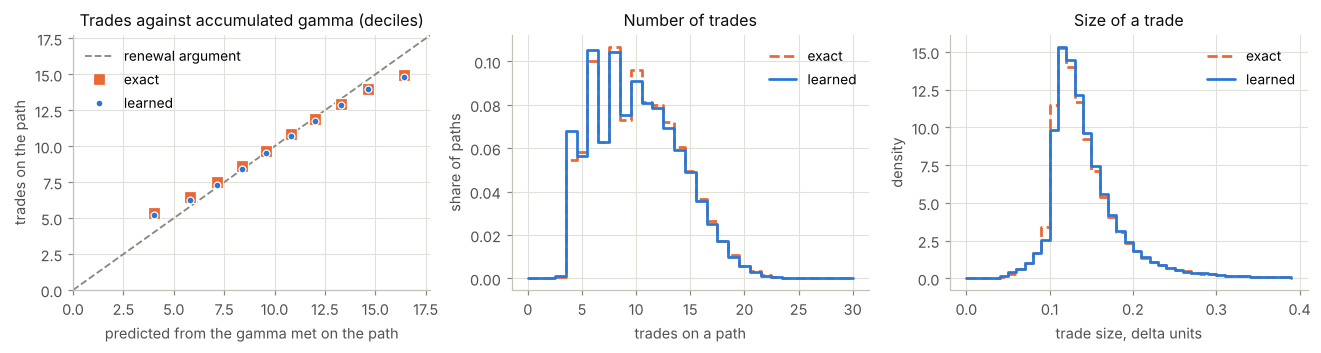

trades per path against the renewal prediction phi(0)/sqrt(6 lambda), and the share
of the cost that is tracking error (the renewal argument predicts one half)
  lambda  predicted   exact  learned   tracking share, exact  learned
 1.0e-04      16.29   15.96    15.54                    0.39     0.41
 2.5e-04      10.30   10.23    10.08                    0.43     0.45
 5.0e-04       7.28    7.27     7.24                    0.45     0.46
path by path (exact policy): trades = 1.92 + 0.81 x prediction, correlation 0.79

number of trades on a path: parity, and net trades |buys - sells|
  exact    even number of trades on 56.0% of paths; median trade size 0.132
           net trades: 0 on 4%, 1 on 9%, 2 on 13%, 3 on 23%, 4 on 39%, 5 on 12%
  learned  even number of trades on 56.6% of paths; median trade size 0.133
           net trades: 0 on 3%, 1 on 8%, 2 on 13%, 3 on 25%, 4 on 41%, 5 on 11%


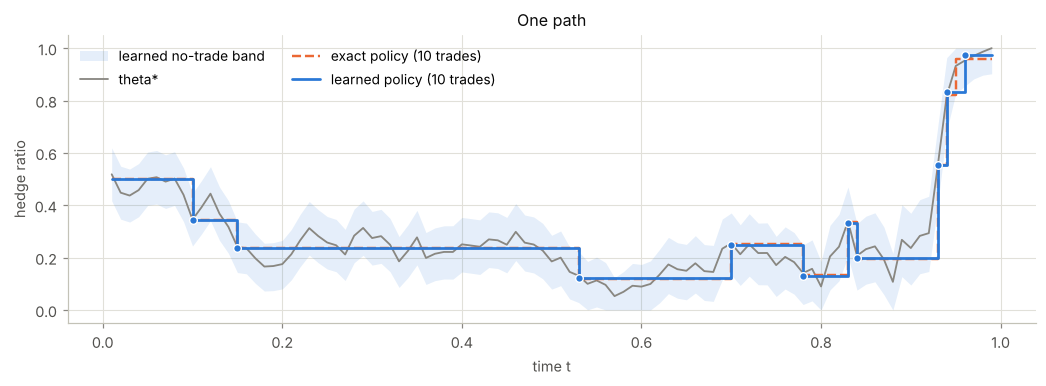

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(12.0, 3.3))
ACC = GAM_EVAL.sum(1) * DT / math.sqrt(6 * LAM)        # trades predicted by the renewal argument from the gamma met on the path
q = np.quantile(ACC, np.linspace(0, 1, 11))
idx = np.clip(np.searchsorted(q, ACC, side="right") - 1, 0, 9)
pm = np.array([ACC[idx == i].mean() for i in range(10)])
ax[0].plot([0, 1.08 * pm.max()], [0, 1.08 * pm.max()], color=GRAY, ls="--", lw=1.2, label="renewal argument")
for pol, col, mk, ms, lab in ((EXACT, ORANGE, "s", 7.5, "exact"), (LEARN, BLUE, "o", 4.5, "learned")):
    ax[0].plot(pm, [pol["trades"][idx == i].mean() for i in range(10)], mk, color=col, ms=ms, mec="white", mew=0.8, label=lab)
ax[0].set_xlim(0, 1.08 * pm.max()); ax[0].set_ylim(0, 1.08 * pm.max())
ax[0].set_xlabel("predicted from the gamma met on the path"); ax[0].set_ylabel("trades on the path")
ax[0].set_title("Trades against accumulated gamma (deciles)"); ax[0].legend()
bins = np.arange(-0.5, 31.5, 1.0)
for pol, col, ls, lab in ((EXACT, ORANGE, "--", "exact"), (LEARN, BLUE, "-", "learned")):
    hgt, _ = np.histogram(pol["trades"], bins=bins, density=True)
    ax[1].step(bins[:-1] + 0.5, hgt, where="mid", color=col, ls=ls, lw=1.8, label=lab)
ax[1].set_xlabel("trades on a path"); ax[1].set_ylabel("share of paths"); ax[1].set_title("Number of trades"); ax[1].legend()
sz_bins = np.linspace(0, 0.4, 41)
for pol, col, ls, lab in ((EXACT, ORANGE, "--", "exact"), (LEARN, BLUE, "-", "learned")):
    size = np.abs(pol["m"] - pol["TPRE"])[pol["Y"]]
    hgt, _ = np.histogram(size, bins=sz_bins, density=True)
    ax[2].step(sz_bins[:-1], hgt, where="post", color=col, ls=ls, lw=1.8, label=lab)
ax[2].set_xlabel("trade size, delta units"); ax[2].set_ylabel("density"); ax[2].set_title("Size of a trade"); ax[2].legend()
finish(fig, "fig_behaviour")

print("trades per path against the renewal prediction phi(0)/sqrt(6 lambda), and the share")
print("of the cost that is tracking error (the renewal argument predicts one half)")
print(f"{'lambda':>8s} {'predicted':>10s} {'exact':>7s} {'learned':>8s} {'tracking share, exact':>23s} {'learned':>8s}")
BEHAV = {}
for lam_ in LAMS:
    e_, l_ = REF[lam_]["exact optimum (DP)"], RES[(lam_, "replay", SEED0)]
    BEHAV[lam_] = (norm.pdf(0.0) / math.sqrt(6 * lam_), e_["trades"].mean(), l_["trades"].mean())
    print(f"{lam_:8.1e} {BEHAV[lam_][0]:10.2f} {BEHAV[lam_][1]:7.2f} {BEHAV[lam_][2]:8.2f} "
          f"{e_['tracking'].mean() / e_['cost'].mean():23.2f} {l_['tracking'].mean() / l_['cost'].mean():8.2f}")
fit_ = np.polyfit(ACC, EXACT["trades"], 1)
print(f"path by path (exact policy): trades = {fit_[1]:.2f} + {fit_[0]:.2f} x prediction, "
      f"correlation {np.corrcoef(ACC, EXACT['trades'])[0, 1]:.2f}")
print()
print("number of trades on a path: parity, and net trades |buys - sells|")
for lab, pol in (("exact", EXACT), ("learned", LEARN)):
    buys = (pol["Y"] & (pol["m"] > pol["TPRE"])).sum(1); sells = (pol["Y"] & (pol["m"] < pol["TPRE"])).sum(1)
    net = np.abs(buys - sells)
    size = np.abs(pol["m"] - pol["TPRE"])[pol["Y"]]
    print(f"  {lab:8s} even number of trades on {100 * np.mean(pol['trades'] % 2 == 0):.1f}% of paths; "
          f"median trade size {np.median(size):.3f}")
    print(f"  {'':8s} net trades: " + ", ".join(f"{v} on {100 * np.mean(net == v):.0f}%" for v in range(6)))

med = np.median(LEARN["trades"])
cand = np.where((LEARN["trades"] == med) & (np.abs(X_EVAL[:, -1]) < 0.4))[0]
i = int(cand[0]) if len(cand) else 0
def position_path(pol, i):
    return np.where(pol["Y"][i], pol["m"][i], pol["TPRE"][i])
fig, ax = plt.subplots(figsize=(9.6, 3.6))
tt = KS * DT
ax.fill_between(tt, np.clip(LEARN["lo"][i], 0, 1), np.clip(LEARN["hi"][i], 0, 1), color=BLUE, alpha=0.12, lw=0, label="learned no-trade band")
ax.plot(tt, TS_EVAL[i], color=GRAY, lw=1.2, label="theta*")
ax.step(tt, position_path(EXACT, i), where="post", color=ORANGE, lw=1.6, ls="--", label=f"exact policy ({int(EXACT['trades'][i])} trades)")
ax.step(tt, position_path(LEARN, i), where="post", color=BLUE, lw=1.8, label=f"learned policy ({int(LEARN['trades'][i])} trades)")
tr = LEARN["Y"][i]
ax.plot(tt[tr], LEARN["m"][i][tr], "o", color=BLUE, ms=5, mec="white", mew=0.9)
ax.set_xlabel("time t"); ax.set_ylabel("hedge ratio"); ax.set_title("One path"); ax.legend(ncol=2)
finish(fig, "fig_sample_path")

**Trades per path.** The renewal argument predicts 16.3, 10.3 and 7.3 trades at the three charge levels. The exact policy makes 16.0, 10.2 and 7.3, the learned one 15.5, 10.1 and 7.2. Path by path the relation is flatter than predicted (slope 0.81, correlation 0.79): a path that leaves the money early meets little gamma, but its hedge still has to travel from one half to zero or one.

**Split of the cost.** Tracking error is 39% to 45% of the cost of the exact policy and 41% to 46% of the learned one, not the half of the continuous-time argument, and the share rises with the charge. A reading that fits these numbers, but was not tested separately: on a grid the tracking term counts the mis-hedge at the start of each step only, which makes tracking cheaper than in continuous time, and the effect fades as the band grows relative to one step.

**Number of trades.** The sawtooth in the middle panel is not a binning artefact. The median trade is 0.13 and the hedge ends on average 0.45 away from where it started, so the net number of trades, buys minus sells, is four on 39% of the paths, three on 23% and five on 12%. The total is the net number plus twice the number of reversals. That favours even totals (56% of the paths) and makes fewer than four trades almost impossible. The learned policy has the same distribution, with this structure.

**Sizes.** Trade sizes peak just above 0.1 and have a tail up to 0.4. The exact and the learned distributions coincide.

## 25. The two estimators compared

Both estimators are unbiased for the same gradient. They differ in noise. The gradient of $1000\,J_\epsilon$ with respect to all weights is estimated 100 times with each estimator, on independent batches, in three situations:

* a network taken from the standard training schedule after 300 iterations, at the $\epsilon$ of that iteration;
* the same network at the final $\epsilon=0.005$, a point where the gradient is large, which makes the comparison of the means sharp;
* the trained network at the final $\epsilon$.

The total variance is summed over all weights. The mean gradient is shown for the three output biases, which move the lower half-width, the upper half-width and the target offset in every state at once. Section 15 is the precise test that both estimators are unbiased; the means are shown here only to confirm that the two estimate the same thing for a network.

In [24]:
def gradient_samples(net, estimator, eps, n, seed, batch=BATCH):
    """n independent estimates of the gradient of 1000 x J_eps with respect to all weights, one batch each."""
    gen = torch.Generator(device=DEVICE); gen.manual_seed(seed)
    out = []
    for _ in range(n):
        net.zero_grad(set_to_none=True)
        loss, _ = surrogate(net, batch, eps, LAM, gen, estimator)
        (LOSS_SCALE * loss).backward()
        out.append(torch.cat([p.grad.reshape(-1) for p in net.parameters()]).cpu().numpy().copy())
    net.zero_grad(set_to_none=True)
    return np.array(out)

STOP_EARLY = 30 if QUICK else 300
NET_EARLY, H_EARLY = train(LAM, 11, "replay", stop_at=STOP_EARLY, verbose=False)    # the standard schedule, interrupted
EPS_EARLY = H_EARLY["eps"][-1]
N_GRAD = 10 if QUICK else 100
CASES = ((f"network after {STOP_EARLY} iterations, at the eps of that iteration ({EPS_EARLY:.4f})", NET_EARLY, EPS_EARLY),
         (f"the same network, at eps = {EPS1}", NET_EARLY, EPS1),
         (f"the trained network, at eps = {EPS1}", NET, EPS1))
print(f"{N_GRAD} gradient estimates per estimator, each from a batch of {BATCH} paths")
print("(independent paths for the two estimators). Total variance: summed over all weights.")
print("Mean gradient: with respect to the output biases of the lower half-width, the upper")
print("half-width and the target offset, with standard errors.")
GN = {}
for label, net_, eps_ in CASES:
    g = {e: gradient_samples(net_, e, eps_, N_GRAD, seed_) for e, seed_ in (("replay", 123), ("score", 456))}
    var = {e: g[e].var(0, ddof=1).sum() for e in g}
    mean = {e: g[e][:, -3:].mean(0) for e in g}
    se = {e: g[e][:, -3:].std(0, ddof=1) / math.sqrt(N_GRAD) for e in g}
    z = (mean["replay"] - mean["score"]) / np.sqrt(se["replay"] ** 2 + se["score"] ** 2)
    GN[label] = dict(eps=eps_, var=var, ratio=var["score"] / var["replay"], mean=mean, se=se, z=z)
    print()
    print(label)
    print(f"   {'estimator':9s} {'total var.':>10s} {'lower half-width':>18s} {'upper half-width':>18s} {'target offset':>18s}")
    for e in ("replay", "score"):
        print(f"   {e:9s} {var[e]:10.3f} " + " ".join(f"{m_:+9.3f} +- {s_:.3f}" for m_, s_ in zip(mean[e], se[e])))
    print(f"   variance ratio score/replay {var['score'] / var['replay']:.1f}; "
          f"difference of the means in s.e.: " + ", ".join(f"{v:+.1f}" for v in z))
del g

100 gradient estimates per estimator, each from a batch of 2048 paths
(independent paths for the two estimators). Total variance: summed over all weights.
Mean gradient: with respect to the output biases of the lower half-width, the upper
half-width and the target offset, with standard errors.

network after 300 iterations, at the eps of that iteration (0.0325)
   estimator total var.   lower half-width   upper half-width      target offset
   replay         0.052    -0.015 +- 0.003    +0.014 +- 0.003    -0.013 +- 0.005
   score          0.538    -0.015 +- 0.011    -0.004 +- 0.013    -0.034 +- 0.012
   variance ratio score/replay 10.3; difference of the means in s.e.: +0.0, +1.4, +1.7

the same network, at eps = 0.005
   estimator total var.   lower half-width   upper half-width      target offset
   replay         0.883    +0.622 +- 0.013    +1.046 +- 0.014    -0.003 +- 0.013
   score          3.375    +0.662 +- 0.029    +1.027 +- 0.030    -0.054 +- 0.031
   variance ratio score/repla

**Noise.** Summed over all weights, the score-function estimate has 10 times the variance of the replay estimate early in training and 46 times at the trained network: for the same noise its batch would have to be 46 times larger. At a point where the gradient is large (second case) the ratio is 4. The replay estimator pays for this in time, 22 to 25 minutes per training run against 13 to 17.

**Means.** The nine differences between the two estimators lie between $-2.0$ and $+1.7$ standard errors. A longer comparison of the second case, made outside this notebook with 800 replay and 2,000 score-function estimates, gave $0.640\pm0.004$ against $0.627\pm0.007$ for the lower half-width, $1.045\pm0.005$ against $1.045\pm0.007$ for the upper one and $0.001\pm0.005$ against $-0.003\pm0.007$ for the offset. Finite differences of the same three biases on a million paths gave $0.656\pm0.009$, $1.038\pm0.009$ and $-0.013\pm0.009$. The largest discrepancy among the three methods is on the lower half-width, where the finite difference is 1.8 and 2.7 standard errors above the two estimators. For the two other parameters the three agree within 1.4 standard errors.

**Stationarity.** At the trained network the replay gradient with respect to the upper half-width is $-0.023\pm0.004$: small, but not zero. Training ended with its schedule, not at a stationary point, in line with the curves of Section 18.

# Part V. Summary

## 26. Criteria

In [25]:
def verdict(ok):
    return "pass" if ok else "FAIL"

ref_ = REF[LAM]["exact optimum (DP)"]
gaps = {est_: [summarise(RES[(LAM, est_, s_)], ref_)["gap_pct"] for s_ in SEEDS] for est_ in ("replay", "score")}
print("Summary at lambda =", LAM)
print(f"  exact optimum: cost {ref_['cost'].mean():.6f} with {ref_['trades'].mean():.1f} trades")
print(f"  formulas: asymptotic band with discrete shift {summarise(REF[LAM]['asymptotic band, discrete shift'], ref_)['gap_pct']:+.2f}%, "
      f"two-regime rule {summarise(REF[LAM][TWO_KEY], ref_)['gap_pct']:+.2f}%")
print(f"  learned, replay gradient:          " + ", ".join(f"{g:+.2f}%" for g in gaps["replay"]) + "  above the optimum, by seed")
print(f"  learned, score-function gradient:  " + ", ".join(f"{g:+.2f}%" for g in gaps["score"]))
print("  two-regime band with the learned target:  "
      + ", ".join(f"{HYBRID[(LAM, s_)]:+.2f}%" for s_ in SEEDS))
print(f"  criterion 1, cost within 3% of the optimum on every seed (replay): {verdict(max(gaps['replay']) <= 3.0)}")
worst_rms = max(max(v) for v in RMS_SEEDS.values())
print("  criterion 2, triggers within 0.01 of the exact ones for t < 0.9 (RMS):")
for k_, v_ in RMS_SEEDS.items():
    print(f"     seed {k_}: lower {v_[0]:.4f}, upper {v_[1]:.4f}")
print(f"     worst {worst_rms:.4f}: {verdict(worst_rms <= 0.01)}")
for lam_ in LAMS:
    if lam_ != LAM:
        s = summarise(RES[(lam_, 'replay', SEED0)], REF[lam_]['exact optimum (DP)'])
        print(f"  lambda = {lam_:.1e}: learned {s['gap_pct']:+.2f}% above the optimum, {s['trades']:.1f} trades "
              f"(exact {REF[lam_]['exact optimum (DP)']['trades'].mean():.1f})")
print("  near-the-money law b = a lam^kappa sqrt(gamma) - B gamma sqrt(dt):")
for who in ("learned", "exact"):
    print(f"     {who:8s} kappa = {KAPPA[who][0]:.3f}, a = {KAPPA[who][1]:.3f}, B = {KAPPA[who][2]:.3f}")
print(f"     theory   kappa = 0.250, a = {6 ** 0.25:.3f}, B = {BGK:.3f}")
print("  trades per path at the three charge levels, renewal prediction / exact / learned:")
print("     " + ";  ".join(f"{BEHAV[l][0]:.1f} / {BEHAV[l][1]:.1f} / {BEHAV[l][2]:.1f}" for l in LAMS))
print("  far-from-the-money law, median ratio of the trigger distance to sqrt(lam/tau):")
print("     learned " + ", ".join(f"{FAR[(l, 'learned')]['ratio']:.2f}" for l in LAMS) + " at the three charge levels (exact 1.00)")

Summary at lambda = 0.00025
  exact optimum: cost 0.004504 with 10.2 trades
  formulas: asymptotic band with discrete shift +9.65%, two-regime rule +1.04%
  learned, replay gradient:          +0.79%, +1.02%, +0.75%  above the optimum, by seed
  learned, score-function gradient:  +1.15%, +1.38%, +1.22%
  two-regime band with the learned target:  +0.47%, +0.48%, +0.48%
  criterion 1, cost within 3% of the optimum on every seed (replay): pass
  criterion 2, triggers within 0.01 of the exact ones for t < 0.9 (RMS):
     seed 1: lower 0.0052, upper 0.0059
     seed 2: lower 0.0052, upper 0.0050
     seed 3: lower 0.0073, upper 0.0066
     worst 0.0073: pass
  lambda = 1.0e-04: learned +0.89% above the optimum, 15.5 trades (exact 16.0)
  lambda = 5.0e-04: learned +0.88% above the optimum, 7.2 trades (exact 7.3)
  near-the-money law b = a lam^kappa sqrt(gamma) - B gamma sqrt(dt):
     learned  kappa = 0.240, a = 1.530, B = 0.737
     exact    kappa = 0.255, a = 1.641, B = 0.621
     theory   

## 27. Findings

The numbers are those of the run stored in this copy, at the main charge level unless stated.

1. **The benchmark holds.** The tracking identity is confirmed on 4.2 million paths, and the numerical error of the exact solution is 0.02% to 0.04% of the cost.

2. **The method works, and the gradient estimator is the crux.** Backpropagation through the simulation gives no gradient for the triggers. With randomised decisions and the replay estimator, three seeds end 0.75% to 1.02% above the exact optimum, with triggers within 0.005 to 0.007 of the exact ones before $t=0.9$. Both criteria set before the build are met. The score-function estimator, which needs no replay, ends at 1.15% to 1.38%; its gradient estimate has 10 to 46 times the variance.

3. **What the network learned.** Near the money it recovered the law $b\propto\lambda^{1/4}\sqrt\Gamma$ with its correction for the grid (exponent 0.240 against $\tfrac14$), without being given $\Gamma$ or $\lambda$. It learned two thirds of the target offset. It learned the break-even regime far from the money in direction only: its band there is 36% to 63% too wide.

4. **What the analysis says about the exact solution.** To 0.1% of the cost, the exact policy is a closed-form band around $\theta^\star$,
$$b_k=\max\Big((6\lambda)^{1/4}\sqrt{\Gamma_k}-\beta\,\Gamma_k\,\sigma\sqrt{\Delta t},\ \sqrt{\lambda/(\sigma^2(T-t_k))}\Big),$$
with a target shifted towards the nearer limit of the hedge ratio. Against the textbook band, the break-even floor is worth 8.6 points of cost and the target offset one point. The floor was found by the regret decomposition, not by the network.

5. **Formula and network are complementary.** The formula has the band and no offset (1.04%). The network has part of the offset and a rough far regime (0.79%). The formula's band with the network's target is at 0.47%, and at 0.43% to 0.63% for the other seeds and charge levels.

6. **Behaviour matches.** The learned policy trades as often as the exact one and as the renewal argument predicts (10.1, 10.2 and 10.3 trades per path), with the same distribution of counts and sizes.

**What this does not show.** One model, one contract, a quadratic criterion, a fixed charge, three charge levels. Here the network was not needed: an exact solution exists, and the best rule found is a formula with a learned correction. The case for the method rests on problems where neither a benchmark nor a formula is available, and that case is not tested here. The representation-level results are weak evidence, for the reason given in Section 23.

**Departures from the plan.**

* The two-regime rule was not in the plan. It came out of the regret analysis and was added to the reference rules, which raised the bar for the network from 9.7% to 1.0%.
* The gradient check uses a three-parameter band on the full problem of 100 dates instead of a shorter problem.
* The replay estimator replays a random subset of branches, about 20 per path out of the 99 dates, with importance weights, instead of all of them.
* The stored outputs use networks trained earlier by the same code and reloaded.

**Next.** Proportional plus fixed costs. The SABR model, with the learned Bartlett delta as the tracking target. A parameterisation that can represent the break-even regime. A longer or sharper annealing schedule.